In [ ]:
import pandas as pd
import numpy as np
import random
import os
import zipfile

In [ ]:
np.random.seed(42)
random.seed(42)

OUTPUT_DIR = "VoltRelay_Dataset"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Creating VoltRelay dataset...")
print("Output folder:", OUTPUT_DIR)

Creating VoltRelay dataset...
Output folder: VoltRelay_Dataset


In [ ]:
cities = [
    "Bengaluru",
    "Delhi NCR",
    "Hyderabad",
    "Pune",
    "Mumbai",
    "Jaipur"
]

vehicle_classes = ["2W", "3W"]

partner_segments = [
    "quick_commerce",
    "food_delivery",
    "ecommerce",
    "logistics"
]

contract_types = [
    "volume_tiered",
    "pay_per_swap",
    "fixed_monthly"
]

location_types = [
    "commercial_hub",
    "transit_hub",
    "owned_lot",
    "market_area",
    "residential_hub"
]

host_types = [
    "kirana",
    "fuel_retailer",
    "owned_lot",
    "mall",
    "parking_operator"
]

charger_generations = ["Gen1", "Gen2", "Gen3"]

connectivity_tiers = [
    "good",
    "fair",
    "poor"
]

plan_types = [
    "partner_billed",
    "pay_as_you_go",
    "prepaid_pack"
]

signup_channels = [
    "partner_onboarding",
    "app_store",
    "field_agent",
    "referral"
]

shift_types = [
    "day_shift",
    "night_shift",
    "full_day"
]

age_bands = [
    "18-24",
    "25-34",
    "35-44",
    "45-54"
]

payment_modes = [
    "upi",
    "cash",
    "wallet",
    "partner_invoice"
]

tariff_codes = [
    "STD",
    "PEAK",
    "OFFPEAK",
    "PREPAID",
    "PARTNER",
    "PROMO_FREE"
]

event_types = [
    "swap_completed",
    "failed_no_charged_battery",
    "failed_station_full",
    "failed_payment",
    "abandoned_queue"
]


In [ ]:
partners = []

for i in range(1, 31):

    partner_id = f"FP{i:03d}"

    partners.append([
        partner_id,
        f"Partner_{i:03d}",
        random.choice(partner_segments),
        random.choice(vehicle_classes),
        random.choice(contract_types),
        pd.Timestamp("2024-01-01") +
        pd.Timedelta(days=random.randint(0, 300)),
        round(random.uniform(0.05, 0.20), 2),
        "",
        "",
        random.choice(["Y", "N"]),
        random.choice([15, 30, 45]),
        "|".join(random.sample(cities, random.randint(2, 4)))
    ])

fleet_partners = pd.DataFrame(partners, columns=[
    "partner_id",
    "partner_name",
    "partner_segment",
    "vehicle_class",
    "contract_type",
    "contract_start_date",
    "discount_pct",
    "amendment_date",
    "discount_pct_after_amendment",
    "peak_surcharge_billable",
    "payment_terms_days",
    "cities_active"
])

for i in range(0, len(fleet_partners), 5):
    amendment = pd.Timestamp("2024-09-01") + pd.Timedelta(
        days=random.randint(0, 300)
    )

    fleet_partners.loc[i, "amendment_date"] = amendment.strftime("%Y-%m-%d")
    fleet_partners.loc[i, "discount_pct_after_amendment"] = round(
        min(fleet_partners.loc[i, "discount_pct"] + random.uniform(0.03, 0.10), 0.35),
        2
    )

fleet_partners.to_csv(
    f"{OUTPUT_DIR}/fleet_partners.csv",
    index=False
)

print("Created fleet_partners.csv")

Created fleet_partners.csv


In [ ]:
stations = []

city_coordinates = {
    "Bengaluru": (12.9716, 77.5946),
    "Delhi NCR": (28.6139, 77.2090),
    "Hyderabad": (17.3850, 78.4867),
    "Pune": (18.5204, 73.8567),
    "Mumbai": (19.0760, 72.8777),
    "Jaipur": (26.9124, 75.7873)
}

station_id_counter = 1

for city in cities:

    # Approximately 25 stations per city
    for j in range(25):

        station_id = f"STN-{station_id_counter:03d}"

        lat, lon = city_coordinates[city]

        lat += random.uniform(-0.10, 0.10)
        lon += random.uniform(-0.10, 0.10)

        commissioned = pd.Timestamp("2024-01-01") + pd.Timedelta(
            days=random.randint(0, 450)
        )

        stations.append([
            station_id,
            city,
            f"Zone_{random.randint(1, 8)}",
            round(lat, 6),
            round(lon, 6),
            random.choice(location_types),
            random.choice(host_types),
            commissioned.strftime("%Y-%m-%d"),
            "",
            random.choice([
                "Launch",
                "Wave1_2024H2",
                "Wave2_2025",
                "Wave3_2025H2"
            ]),
            random.choice(charger_generations),
            random.choice([8, 12, 16, 20, 24]),
            random.choice([4, 6, 8, 10]),
            random.choice([6, 10, 14, 18]),
            random.choice([3, 5, 7]),
            random.randint(10000, 35000),
            random.randint(2500, 8000),
            round(random.uniform(6.0, 10.0), 2),
            random.choice(connectivity_tiers),
            random.choice(["v3.0.0", "v3.1.0", "v3.2.0", "v3.3.0"]),
            (
                commissioned + pd.Timedelta(days=random.randint(0, 400))
            ).strftime("%Y-%m-%d"),
            ""
        ])

        station_id_counter += 1

stations = pd.DataFrame(stations, columns=[
    "station_id",
    "city",
    "zone",
    "latitude",
    "longitude",
    "location_type",
    "host_type",
    "commissioned_date",
    "decommissioned_date",
    "expansion_wave",
    "charger_generation",
    "slots_2w",
    "slots_3w",
    "inventory_target_2w",
    "inventory_target_3w",
    "monthly_rent_inr",
    "monthly_maintenance_inr",
    "grid_tariff_inr_kwh",
    "connectivity_tier",
    "firmware_version",
    "firmware_updated_date",
    "competitor_within_1_5km_since"
])

stations.to_csv(
    f"{OUTPUT_DIR}/stations.csv",
    index=False
)

print("Created stations.csv")

NUM_RIDERS = 20000

riders = []

for i in range(1, NUM_RIDERS + 1):

    rider_id = f"R-{i:05d}"

    vehicle = random.choice(vehicle_classes)

    partner_id = ""

    if random.random() < 0.55:
        partner_id = random.choice(
            fleet_partners["partner_id"].tolist()
        )

    city = random.choice(cities)

    signup_date = pd.Timestamp("2024-01-01") + pd.Timedelta(
        days=random.randint(0, 700)
    )

    riders.append([
        rider_id,
        partner_id,
        vehicle,
        "EV-" + random.choice(
            ["Zip", "Eco", "Volt", "Rapid", "Cargo"]
        ) + "-" + vehicle,
        city,
        f"Zone_{random.randint(1, 8)}",
        signup_date.strftime("%Y-%m-%d"),
        random.choice(signup_channels),
        random.choice(plan_types),
        random.choice(shift_types),
        random.choice(age_bands),
        random.choice([True, True, True, False])
    ])

riders = pd.DataFrame(riders, columns=[
    "rider_id",
    "partner_id",
    "vehicle_class",
    "vehicle_model",
    "home_city",
    "home_zone",
    "signup_date",
    "signup_channel",
    "plan_type",
    "declared_shift",
    "age_band",
    "kyc_verified"
])

riders.to_csv(
    f"{OUTPUT_DIR}/riders.csv",
    index=False
)

print("Created riders.csv")


Created stations.csv
Created riders.csv


In [ ]:
NUM_BATTERIES = 6500

batteries = []

suppliers = ["Cellora", "Amptek", "Kyron", "VoltCell", "EnerPack"]

for i in range(1, NUM_BATTERIES + 1):

    battery_id = f"BAT-{i:05d}"

    vehicle = random.choice(vehicle_classes)

    if vehicle == "2W":
        pack_type = "2W_2.1kWh"
        capacity = 2.1
        cost = random.randint(30000, 38000)
    else:
        pack_type = "3W_4.8kWh"
        capacity = 4.8
        cost = random.randint(65000, 85000)

    manufacture_date = pd.Timestamp("2023-01-01") + pd.Timedelta(
        days=random.randint(0, 600)
    )

    commission_date = manufacture_date + pd.Timedelta(
        days=random.randint(10, 120)
    )

    initial_soh = round(random.uniform(97, 100), 1)

    current_soh = round(
        max(
            65,
            initial_soh - random.uniform(2, 25)
        ),
        1
    )

    retired = current_soh < 72 and random.random() < 0.6

    batteries.append([
        battery_id,
        pack_type,
        random.choice(suppliers),
        f"LOT-{manufacture_date.strftime('%Y-%m')}",
        manufacture_date.strftime("%Y-%m-%d"),
        commission_date.strftime("%Y-%m-%d"),
        capacity,
        cost,
        initial_soh,
        random.choice(["BMS-v1.0", "BMS-v1.2", "BMS-v2.0"]),
        current_soh,
        (
            (pd.Timestamp("2025-12-31")).strftime("%Y-%m-%d")
            if retired else ""
        ),
        (
            random.choice([
                "low_soh",
                "thermal_issue",
                "physical_damage"
            ])
            if retired else ""
        )
    ])

batteries = pd.DataFrame(batteries, columns=[
    "battery_id",
    "pack_type",
    "supplier",
    "manufacturing_lot",
    "manufacture_date",
    "commission_date",
    "rated_capacity_kwh",
    "purchase_cost_inr",
    "initial_soh_pct",
    "bms_firmware",
    "current_soh_pct",
    "retired_date",
    "retirement_reason"
])

batteries.to_csv(
    f"{OUTPUT_DIR}/batteries.csv",
    index=False
)

print("Created batteries.csv")


Created batteries.csv


In [ ]:
dates = pd.date_range(
    start="2024-01-01",
    end="2025-12-31",
    freq="D"
)

context = []

for city in cities:

    for date in dates:

        month = date.month

        if city == "Delhi NCR":
            max_temp = random.uniform(18, 42)
        elif city == "Mumbai":
            max_temp = random.uniform(27, 34)
        elif city == "Bengaluru":
            max_temp = random.uniform(25, 33)
        elif city == "Hyderabad":
            max_temp = random.uniform(27, 39)
        elif city == "Pune":
            max_temp = random.uniform(24, 36)
        else:
            max_temp = random.uniform(24, 42)

        min_temp = max_temp - random.uniform(6, 14)

        rainfall = 0

        if month in [6, 7, 8, 9]:
            rainfall = max(0, np.random.normal(30, 50))

        heat_alert = max_temp > 38
        flood_disruption = rainfall > 100

        context.append([
            city,
            date.strftime("%Y-%m-%d"),
            round(max_temp, 1),
            round(min_temp, 1),
            round(rainfall, 1),
            heat_alert,
            flood_disruption,
            random.choice([
                "",
                "",
                "",
                "Local Event",
                "Festival",
                "Sale Event"
            ]),
            date.weekday() == 6,
            round(max(0, np.random.normal(1, 1.5)), 1),
            random.random() < 0.15,
            random.random() < 0.10
        ])

city_daily_context = pd.DataFrame(context, columns=[
    "city",
    "date",
    "max_temp_c",
    "min_temp_c",
    "rainfall_mm",
    "heat_alert",
    "flood_disruption",
    "festival_or_event",
    "is_public_holiday",
    "grid_outage_hours",
    "competitor_promo_active",
    "ecommerce_sale_event"
])

city_daily_context.to_csv(
    f"{OUTPUT_DIR}/city_daily_context.csv",
    index=False
)

print("Created city_daily_context.csv")

Created city_daily_context.csv


In [ ]:
hourly_rows = []

sample_stations = stations["station_id"].tolist()

hour_dates = pd.date_range(
    "2024-01-01",
    "2025-12-31 23:00:00",
    freq="6h"
)

for station_id in sample_stations:

    for timestamp in hour_dates:

        hour = timestamp.hour

        peak = hour in [7, 8, 9, 17, 18, 19, 20]

        charged_2w = random.randint(1, 18) if peak else random.randint(3, 20)
        charged_2w_min = max(0, charged_2w - random.randint(0, 5))
        charged_3w_min = random.randint(0, 8)

        packs_charging = random.randint(2, 15)

        quarantined = random.choice([0, 0, 0, 1, 2])

        chargers_online = random.randint(8, 24)

        ambient_temp = random.uniform(20, 40)

        cabinet_temp = ambient_temp + random.uniform(4, 10)

        avg_charge_minutes = random.uniform(35, 65)

        outage = random.choice([
            0, 0, 0, 5, 10, 15, 30
        ])

        grid_kwh = round(
            random.uniform(5, 35),
            2
        )

        hourly_rows.append([
            station_id,
            timestamp.strftime("%Y-%m-%d %H:%M:%S"),
            round(charged_2w, 1),
            charged_2w_min,
            charged_3w_min,
            packs_charging,
            quarantined,
            chargers_online,
            round(ambient_temp, 1),
            round(cabinet_temp, 1),
            round(avg_charge_minutes, 1),
            outage,
            grid_kwh,
            random.choice(["ok", "ok", "ok", "delayed"])
        ])

station_hourly_status = pd.DataFrame(hourly_rows, columns=[
    "station_id",
    "hour_start",
    "charged_2w_avg",
    "charged_2w_min",
    "charged_3w_min",
    "packs_charging",
    "packs_quarantined",
    "chargers_online",
    "ambient_temp_c",
    "cabinet_temp_c",
    "avg_charge_minutes",
    "outage_minutes",
    "grid_kwh",
    "telemetry_status"
])

station_hourly_status.to_csv(
    f"{OUTPUT_DIR}/station_hourly_status.csv",
    index=False
)

print("Created station_hourly_status.csv")


Created station_hourly_status.csv


In [ ]:
NUM_EVENTS = 150000

rider_ids = riders["rider_id"].tolist()
station_ids = stations["station_id"].tolist()
battery_ids = batteries["battery_id"].tolist()

swap_rows = []

for i in range(1, NUM_EVENTS + 1):

    rider_id = random.choice(rider_ids)
    station_id = random.choice(station_ids)

    event_ts = pd.Timestamp("2024-01-01") + pd.Timedelta(
        seconds=random.randint(
            0,
            int((pd.Timestamp("2025-12-31") -
                 pd.Timestamp("2024-01-01")).total_seconds())
        )
    )

    event_type = random.choices(
        event_types,
        weights=[0.88, 0.04, 0.03, 0.02, 0.03]
    )[0]

    queue_wait = int(
        max(
            5,
            np.random.normal(
                90 if event_type == "swap_completed" else 240,
                70
            )
        )
    )

    battery_in = random.choice(battery_ids)

    battery_out = ""

    if event_type == "swap_completed":
        battery_out = random.choice(battery_ids)

    soc_in = round(random.uniform(5, 40), 1)
    soh_in = round(random.uniform(70, 100), 1)

    soc_out = ""
    soh_out = ""

    if event_type == "swap_completed":
        soc_out = round(random.uniform(90, 100), 1)
        soh_out = round(random.uniform(75, 100), 1)

    km = round(
        max(
            1,
            np.random.normal(60, 35)
        ),
        1
    )

    tariff = random.choice(tariff_codes)

    list_price = random.choice([
        80, 90, 100, 110, 120
    ])

    discount = 0

    if tariff in ["PARTNER", "PREPAID", "PROMO_FREE"]:
        discount = round(
            list_price * random.uniform(0.05, 0.25),
            2
        )

    amount = round(
        max(0, list_price - discount),
        2
    )

    energy = ""

    if event_type == "swap_completed":
        energy = round(
            random.uniform(1.2, 4.8),
            2
        )

    swap_rows.append([
        f"EVT-{i:07d}",
        rider_id,
        station_id,
        event_ts.strftime("%Y-%m-%d %H:%M:%S"),
        event_type,
        random.randint(1, 3),
        queue_wait,
        battery_in,
        battery_out,
        soc_in,
        soh_in,
        soc_out,
        soh_out,
        km,
        tariff,
        list_price,
        discount,
        amount,
        random.choice(payment_modes),
        energy,
        random.choice([
            "v3.0.0",
            "v3.1.0",
            "v3.2.0",
            "v3.3.0"
        ]),
        random.choice([
            "realtime",
            "realtime",
            "offline_batch"
        ])
    ])

swap_events = pd.DataFrame(swap_rows, columns=[
    "event_id",
    "rider_id",
    "station_id",
    "event_ts",
    "event_type",
    "attempt_seq",
    "queue_wait_sec",
    "battery_in_id",
    "battery_out_id",
    "soc_in_pct",
    "soh_in_pct",
    "soc_out_pct",
    "soh_out_pct",
    "km_since_last_swap",
    "tariff_code",
    "list_price_inr",
    "discount_inr",
    "amount_charged_inr",
    "payment_mode",
    "energy_to_recharge_kwh",
    "station_firmware",
    "sync_mode"
])

duplicate_rows = swap_events.sample(
    500,
    random_state=42
)

swap_events = pd.concat(
    [swap_events, duplicate_rows],
    ignore_index=True
)

missing_indices = np.random.choice(
    swap_events.index,
    size=1000,
    replace=False
)

swap_events.loc[
    missing_indices,
    "queue_wait_sec"
] = np.nan

swap_events.to_csv(
    f"{OUTPUT_DIR}/swap_events.csv",
    index=False
)

print("Created swap_events.csv")


Created swap_events.csv


In [ ]:
NUM_TICKETS = 44000

ticket_rows = []

categories = [
    "station_issue",
    "battery_degradation",
    "payment_issue",
    "app_issue",
    "long_queue",
    "other"
]

for i in range(1, NUM_TICKETS + 1):

    rider_id = random.choice(rider_ids)
    station_id = random.choice(station_ids)

    created_ts = pd.Timestamp("2024-01-01") + pd.Timedelta(
        seconds=random.randint(
            0,
            int((pd.Timestamp("2025-12-31") -
                 pd.Timestamp("2024-01-01")).total_seconds())
        )
    )

    category = random.choice(categories)

    priority = random.choice([
        "low",
        "medium",
        "high"
    ])

    status = random.choice([
        "resolved",
        "resolved",
        "resolved",
        "unresolved"
    ])

    resolution_hours = ""

    if status == "resolved":
        resolution_hours = round(
            random.uniform(1, 48),
            1
        )

    csat = ""

    if status == "resolved" and random.random() < 0.75:
        csat = random.randint(1, 5)

    comments = {
        "station_issue": "Station issue and battery availability problem",
        "battery_degradation": "Battery range has reduced",
        "payment_issue": "Payment transaction problem",
        "app_issue": "Application is not responding correctly",
        "long_queue": "Long waiting time at station",
        "other": "General service issue"
    }

    ticket_rows.append([
        f"TCK-{i:06d}",
        rider_id,
        station_id,
        random.choice(battery_ids) if random.random() < 0.2 else "",
        created_ts.strftime("%Y-%m-%d %H:%M:%S"),
        random.choice([
            "app_chat",
            "whatsapp",
            "call_center",
            "email"
        ]),
        category,
        comments[category],
        priority,
        status,
        resolution_hours,
        csat
    ])

support_tickets = pd.DataFrame(ticket_rows, columns=[
    "ticket_id",
    "rider_id",
    "station_id",
    "battery_id",
    "created_ts",
    "channel",
    "category",
    "rider_comment",
    "priority",
    "resolution_status",
    "resolution_hours",
    "csat_score"
])

support_tickets.to_csv(
    f"{OUTPUT_DIR}/support_tickets.csv",
    index=False
)

print("Created support_tickets.csv")



Created support_tickets.csv


In [ ]:
zip_name = "VoltRelay_Dataset.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:

    for file in os.listdir(OUTPUT_DIR):

        file_path = os.path.join(
            OUTPUT_DIR,
            file
        )

        zipf.write(
            file_path,
            arcname=file
        )

print("\n====================================")
print("DATASET GENERATION COMPLETED")
print("====================================")

print("\nFiles created:")

for file in os.listdir(OUTPUT_DIR):
    print("✔", file)

print("\nZIP file:")
print("✔", zip_name)

print("\nYou can download the ZIP from the Colab Files panel.")


DATASET GENERATION COMPLETED

Files created:
✔ fleet_partners.csv
✔ support_tickets.csv
✔ city_daily_context.csv
✔ station_hourly_status.csv
✔ stations.csv
✔ batteries.csv
✔ swap_events.csv
✔ riders.csv

ZIP file:
✔ VoltRelay_Dataset.zip

You can download the ZIP from the Colab Files panel.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

plt.rcParams["figure.figsize"] = (12, 6)

In [ ]:
DATA_DIR = "VoltRelay_Dataset"

partners = pd.read_csv(
    f"{DATA_DIR}/fleet_partners.csv"
)

stations = pd.read_csv(
    f"{DATA_DIR}/stations.csv"
)

riders = pd.read_csv(
    f"{DATA_DIR}/riders.csv"
)

batteries = pd.read_csv(
    f"{DATA_DIR}/batteries.csv"
)

city_context = pd.read_csv(
    f"{DATA_DIR}/city_daily_context.csv"
)

station_status = pd.read_csv(
    f"{DATA_DIR}/station_hourly_status.csv"
)

swaps = pd.read_csv(
    f"{DATA_DIR}/swap_events.csv"
)

tickets = pd.read_csv(
    f"{DATA_DIR}/support_tickets.csv"
)

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [ ]:
datasets = {
    "Partners": partners,
    "Stations": stations,
    "Riders": riders,
    "Batteries": batteries,
    "City Context": city_context,
    "Station Status": station_status,
    "Swap Events": swaps,
    "Support Tickets": tickets
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name)

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    display(df.head(3))

print("\nMISSING VALUES")

for name, df in datasets.items():

    missing = df.isnull().sum()

    missing = missing[
        missing > 0
    ].sort_values(
        ascending=False
    )

    print("\n", name)

    display(missing.head(10))




Partners
Rows: 30
Columns: 12


,partner_id,partner_name,partner_segment,vehicle_class,contract_type,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active
0,FP001,Partner_001,quick_commerce,2W,fixed_monthly,2024-05-20,0.09,2025-06-11,0.14,Y,45,Jaipur|Mumbai
1,FP002,Partner_002,quick_commerce,3W,volume_tiered,2024-01-16,0.06,NaN,NaN,Y,45,Bengaluru|Mumbai|Delhi NCR|Hyderabad
2,FP003,Partner_003,logistics,2W,pay_per_swap,2024-05-22,0.17,NaN,NaN,Y,15,Pune|Hyderabad|Mumbai|Bengaluru



Stations
Rows: 150
Columns: 22


,station_id,city,zone,latitude,longitude,location_type,host_type,commissioned_date,decommissioned_date,expansion_wave,...,slots_3w,inventory_target_2w,inventory_target_3w,monthly_rent_inr,monthly_maintenance_inr,grid_tariff_inr_kwh,connectivity_tier,firmware_version,firmware_updated_date,competitor_within_1_5km_since
0,STN-001,Bengaluru,Zone_8,12.912319,77.621448,owned_lot,kirana,2024-05-15,NaN,Launch,...,8,6,3,20929,3571,8.55,fair,v3.1.0,2025-05-29,NaN
1,STN-002,Bengaluru,Zone_1,12.959967,77.635733,commercial_hub,kirana,2024-10-14,NaN,Wave1_2024H2,...,8,10,5,14176,2842,7.23,good,v3.2.0,2025-01-29,NaN
2,STN-003,Bengaluru,Zone_7,13.008013,77.627987,residential_hub,fuel_retailer,2024-06-30,NaN,Wave1_2024H2,...,10,6,3,34135,5221,9.13,fair,v3.1.0,2024-11-13,NaN



Riders
Rows: 20000
Columns: 12


,rider_id,partner_id,vehicle_class,vehicle_model,home_city,home_zone,signup_date,signup_channel,plan_type,declared_shift,age_band,kyc_verified
0,R-00001,FP030,3W,EV-Volt-3W,Hyderabad,Zone_5,2024-04-05,partner_onboarding,pay_as_you_go,full_day,25-34,True
1,R-00002,NaN,3W,EV-Rapid-3W,Jaipur,Zone_2,2024-08-27,partner_onboarding,partner_billed,day_shift,45-54,True
2,R-00003,NaN,2W,EV-Rapid-2W,Mumbai,Zone_1,2025-11-27,partner_onboarding,prepaid_pack,night_shift,18-24,False


... (22 outputs left out)


 Swap Events


,0
battery_out_id,18162
soh_out_pct,18162
soc_out_pct,18162
energy_to_recharge_kwh,18162
queue_wait_sec,1000



 Support Tickets


,0
battery_id,35009
csat_score,19320
resolution_hours,11027


In [ ]:
swaps["event_ts"] = pd.to_datetime(
    swaps["event_ts"],
    errors="coerce"
)

riders["signup_date"] = pd.to_datetime(
    riders["signup_date"],
    errors="coerce"
)

tickets["created_ts"] = pd.to_datetime(
    tickets["created_ts"],
    errors="coerce"
)

batteries["manufacture_date"] = pd.to_datetime(
    batteries["manufacture_date"],
    errors="coerce"
)

batteries["commission_date"] = pd.to_datetime(
    batteries["commission_date"],
    errors="coerce"
)


# Remove exact duplicate swap events
before = len(swaps)

swaps = swaps.drop_duplicates(
    subset=["event_id"]
)

after = len(swaps)

print(
    "Duplicate swap events removed:",
    before - after
)

business_swaps = swaps[
    ~swaps["station_id"].str.startswith(
        "STN-TST",
        na=False
    )
].copy()
business_swaps["queue_wait_sec"] = (
    business_swaps["queue_wait_sec"]
    .fillna(
        business_swaps["queue_wait_sec"].median()
    )
)


Duplicate swap events removed: 0


/tmp/ipykernel_3981/933140175.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  swaps["event_ts"] = pd.to_datetime(


In [ ]:
business_swaps["date"] = (
    business_swaps["event_ts"]
    .dt.date
)

business_swaps["month"] = (
    business_swaps["event_ts"]
    .dt.to_period("M")
    .astype(str)
)

business_swaps["hour"] = (
    business_swaps["event_ts"]
    .dt.hour
)

business_swaps["day_of_week"] = (
    business_swaps["event_ts"]
    .dt.day_name()
)


In [ ]:
print("\nNETWORK PERFORMANCE")

total_attempts = len(business_swaps)

completed = (
    business_swaps["event_type"]
    == "swap_completed"
).sum()

failures = total_attempts - completed

failure_rate = (
    failures / total_attempts * 100
)

revenue = (
    business_swaps["amount_charged_inr"]
    .sum()
)

revenue_per_attempt = (
    revenue / total_attempts
)

revenue_per_completed_swap = (
    revenue / completed
)

print("Total attempts:", total_attempts)
print("Completed swaps:", completed)
print("Failed attempts:", failures)
print("Failure rate:", round(failure_rate, 2), "%")
print("Total revenue:", round(revenue, 2))
print(
    "Revenue / attempt:",
    round(revenue_per_attempt, 2)
)
print(
    "Revenue / completed swap:",
    round(revenue_per_completed_swap, 2)
)


NETWORK PERFORMANCE
Total attempts: 150000
Completed swaps: 131911
Failed attempts: 18089
Failure rate: 12.06 %
Total revenue: 13869562.21
Revenue / attempt: 92.46
Revenue / completed swap: 105.14


In [ ]:
monthly = (
    business_swaps
    .groupby("month")
    .agg(
        attempts=("event_id", "count"),
        completed_swaps=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        revenue=(
            "amount_charged_inr",
            "sum"
        ),
        avg_wait=(
            "queue_wait_sec",
            "mean"
        )
    )
    .reset_index()
)

monthly["failure_rate_pct"] = (
    (
        monthly["attempts"]
        - monthly["completed_swaps"]
    )
    / monthly["attempts"]
) * 100

monthly["revenue_per_swap"] = (
    monthly["revenue"]
    / monthly["completed_swaps"]
)

display(monthly.head(20))


,month,attempts,completed_swaps,revenue,avg_wait,failure_rate_pct,revenue_per_swap
0,2024-01,6480,5673,601701.94,112.964506,12.453704,106.064153
1,2024-02,5872,5116,545243.36,111.542405,12.874659,106.576106
2,2024-03,6332,5555,584229.70,110.649400,12.271004,105.171863
3,2024-04,6141,5396,566527.02,111.808826,12.131575,104.990182
4,2024-05,6409,5612,593073.31,111.185988,12.435637,105.679492
5,2024-06,6185,5462,573579.79,111.438480,11.689572,105.012777
6,2024-07,6347,5596,586726.29,110.732787,11.832362,104.847443
7,2024-08,6386,5656,589982.84,110.407924,11.431256,104.310969
8,2024-09,6172,5400,569379.72,113.205606,12.508101,105.440689
9,2024-10,6396,5672,589252.78,110.419012,11.319575,103.888008


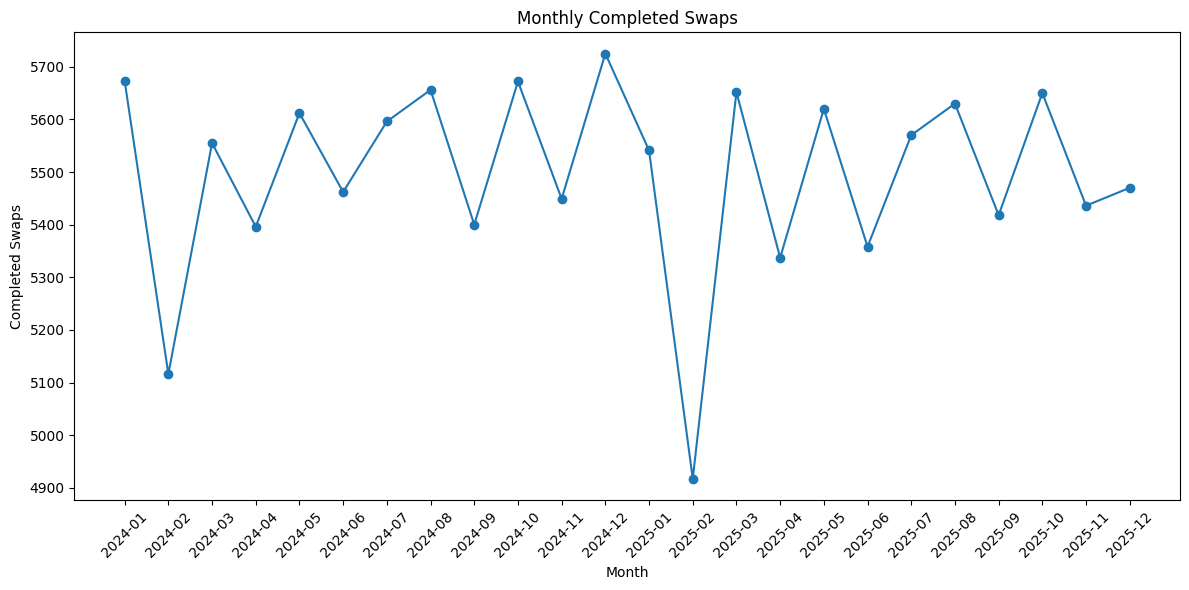

In [ ]:
plt.figure()

plt.plot(
    monthly["month"],
    monthly["completed_swaps"],
    marker="o"
)

plt.title(
    "Monthly Completed Swaps"
)

plt.xlabel("Month")
plt.ylabel("Completed Swaps")

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


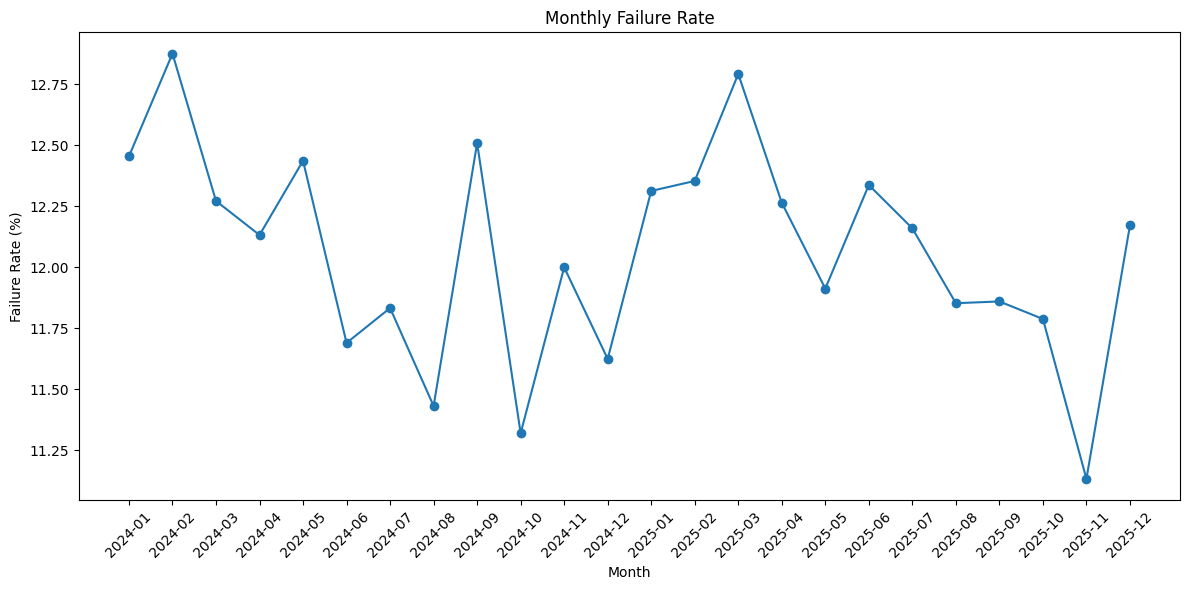

In [ ]:
plt.figure()

plt.plot(
    monthly["month"],
    monthly["failure_rate_pct"],
    marker="o"
)

plt.title(
    "Monthly Failure Rate"
)

plt.xlabel("Month")
plt.ylabel("Failure Rate (%)")

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


In [ ]:
city_analysis = (
    business_swaps
    .merge(
        stations[
            ["station_id", "city"]
        ],
        on="station_id",
        how="left"
    )
    .groupby("city")
    .agg(
        attempts=("event_id", "count"),
        completed=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        avg_wait=(
            "queue_wait_sec",
            "mean"
        ),
        revenue=(
            "amount_charged_inr",
            "sum"
        )
    )
    .reset_index()
)

city_analysis["failure_rate_pct"] = (
    1 -
    city_analysis["completed"]
    / city_analysis["attempts"]
) * 100

display(
    city_analysis.sort_values(
        "failure_rate_pct",
        ascending=False
    )
)

,city,attempts,completed,avg_wait,revenue,failure_rate_pct
3,Jaipur,25101,22013,111.232899,2318612.61,12.302299
5,Pune,25362,22280,111.272534,2348113.19,12.152038
2,Hyderabad,25017,21989,111.346524,2314119.63,12.103769
4,Mumbai,24703,21719,111.420516,2280879.20,12.079505
1,Delhi NCR,24899,21936,110.899635,2305501.84,11.900076
0,Bengaluru,24918,21974,110.612890,2302335.74,11.814752


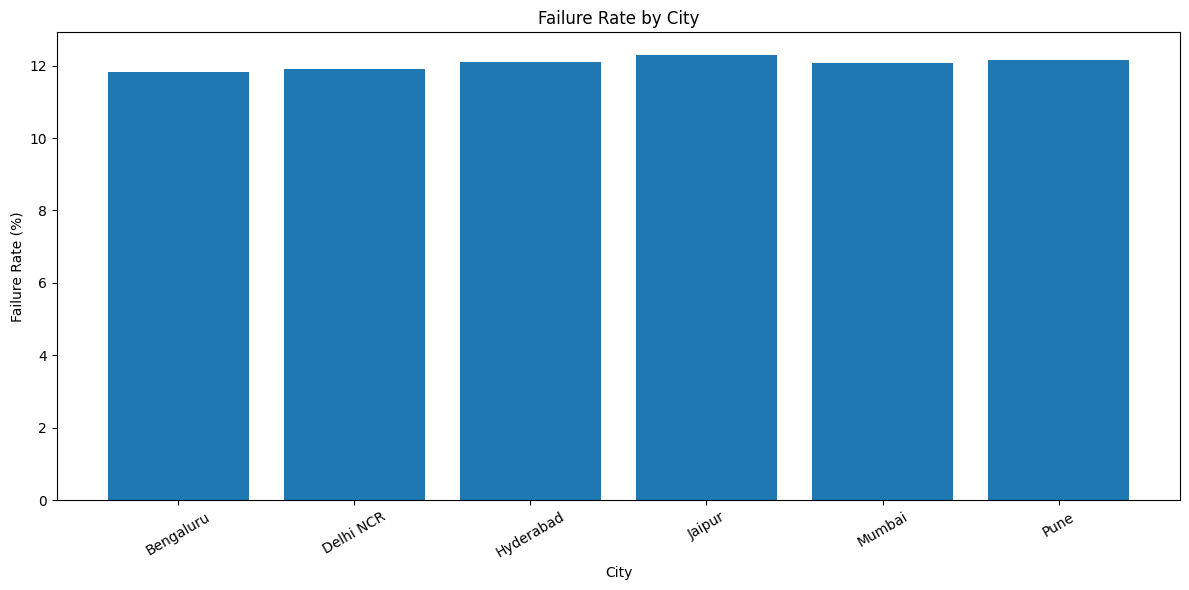

In [ ]:
plt.figure()

plt.bar(
    city_analysis["city"],
    city_analysis["failure_rate_pct"]
)

plt.title(
    "Failure Rate by City"
)

plt.xlabel("City")
plt.ylabel("Failure Rate (%)")

plt.xticks(
    rotation=30
)

plt.tight_layout()

plt.show()


In [ ]:
hour_analysis = (
    business_swaps
    .groupby("hour")
    .agg(
        attempts=("event_id", "count"),
        completed=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        avg_wait=(
            "queue_wait_sec",
            "mean"
        )
    )
    .reset_index()
)

hour_analysis["failure_rate_pct"] = (
    1 -
    hour_analysis["completed"]
    / hour_analysis["attempts"]
) * 100

display(hour_analysis)


,hour,attempts,completed,avg_wait,failure_rate_pct
0,0,6229,5464,111.524322,12.281265
1,1,6291,5551,110.139723,11.762836
2,2,6307,5584,109.756937,11.463453
3,3,6222,5470,111.103343,12.086146
4,4,6123,5399,109.905112,11.824269
5,5,6311,5581,110.810331,11.567105
6,6,6234,5460,111.244466,12.415784
7,7,6168,5378,111.213521,12.808042
8,8,6175,5445,111.197085,11.821862
9,9,6171,5463,109.521309,11.473019


In [ ]:
vehicle_analysis = (
    business_swaps
    .merge(
        riders[
            ["rider_id", "vehicle_class"]
        ],
        on="rider_id",
        how="left"
    )
    .groupby("vehicle_class")
    .agg(
        attempts=("event_id", "count"),
        completed=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        avg_wait=(
            "queue_wait_sec",
            "mean"
        )
    )
    .reset_index()
)

vehicle_analysis["failure_rate_pct"] = (
    1 -
    vehicle_analysis["completed"]
    / vehicle_analysis["attempts"]
) * 100

display(vehicle_analysis)


,vehicle_class,attempts,completed,avg_wait,failure_rate_pct
0,2W,75904,66646,111.335529,12.196986
1,3W,74096,65265,110.921750,11.918322


In [ ]:
station_analysis = (
    business_swaps
    .groupby("station_id")
    .agg(
        attempts=("event_id", "count"),
        completed=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        avg_wait=(
            "queue_wait_sec",
            "mean"
        ),
        revenue=(
            "amount_charged_inr",
            "sum"
        )
    )
    .reset_index()
)

station_analysis["failure_rate_pct"] = (
    1 -
    station_analysis["completed"]
    / station_analysis["attempts"]
) * 100

station_analysis = station_analysis.merge(
    stations[
        [
            "station_id",
            "city",
            "charger_generation",
            "location_type",
            "host_type",
            "slots_2w",
            "slots_3w",
            "monthly_rent_inr",
            "monthly_maintenance_inr",
            "connectivity_tier"
        ]
    ],
    on="station_id",
    how="left"
)

display(
    station_analysis.sort_values(
        "failure_rate_pct",
        ascending=False
    ).head(15)
)



,station_id,attempts,completed,avg_wait,revenue,failure_rate_pct,city,charger_generation,location_type,host_type,slots_2w,slots_3w,monthly_rent_inr,monthly_maintenance_inr,connectivity_tier
126,STN-127,1000,852,112.413000,92617.87,14.800000,Jaipur,Gen1,commercial_hub,parking_operator,8,10,21160,7457,poor
86,STN-087,1043,895,114.331735,96353.35,14.189837,Pune,Gen2,owned_lot,fuel_retailer,12,8,18211,4108,poor
123,STN-124,1038,891,119.072254,95622.07,14.161850,Mumbai,Gen2,commercial_hub,owned_lot,24,6,32414,3160,poor
28,STN-029,1014,871,116.182446,93854.77,14.102564,Delhi NCR,Gen2,owned_lot,parking_operator,8,4,20561,7445,good
20,STN-021,1019,877,109.919529,93973.21,13.935231,Bengaluru,Gen3,market_area,mall,20,10,13049,4910,poor
136,STN-137,1005,866,113.232836,92702.39,13.830846,Jaipur,Gen1,owned_lot,kirana,16,10,33925,3660,fair
93,STN-094,1027,886,113.140214,95505.32,13.729309,Pune,Gen1,residential_hub,owned_lot,8,10,28279,5495,good
134,STN-135,1023,883,114.272727,94939.84,13.685239,Jaipur,Gen3,commercial_hub,mall,20,10,32991,6898,good
112,STN-113,980,846,114.562245,90387.42,13.673469,Mumbai,Gen1,residential_hub,kirana,8,4,29588,2898,good
1,STN-002,984,850,116.488821,90980.19,13.617886,Bengaluru,Gen3,commercial_hub,kirana,8,8,14176,2842,good


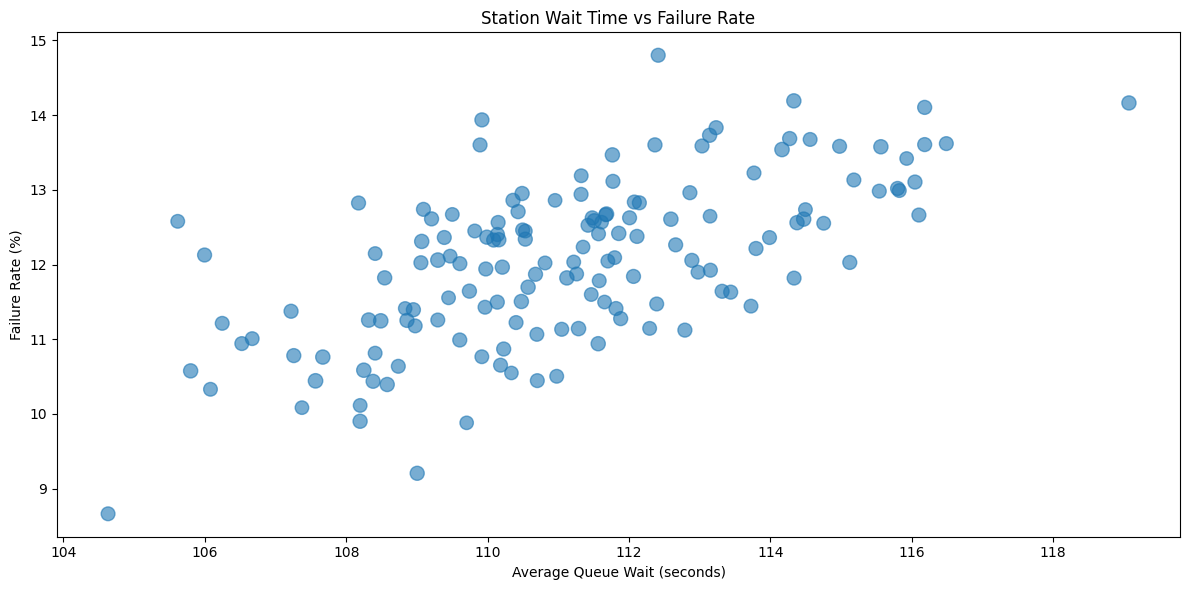

In [ ]:
plt.figure()

plt.scatter(
    station_analysis["avg_wait"],
    station_analysis["failure_rate_pct"],
    s=station_analysis["attempts"] / 10,
    alpha=0.6
)

plt.title(
    "Station Wait Time vs Failure Rate"
)

plt.xlabel(
    "Average Queue Wait (seconds)"
)

plt.ylabel(
    "Failure Rate (%)"
)

plt.tight_layout()

plt.show()



In [ ]:
battery_analysis = (
    batteries
    .groupby("supplier")
    .agg(
        battery_count=(
            "battery_id",
            "count"
        ),
        avg_soh=(
            "current_soh_pct",
            "mean"
        ),
        avg_initial_soh=(
            "initial_soh_pct",
            "mean"
        ),
        avg_cost=(
            "purchase_cost_inr",
            "mean"
        )
    )
    .reset_index()
)

battery_analysis["soh_drop"] = (
    battery_analysis["avg_initial_soh"]
    - battery_analysis["avg_soh"]
)

display(battery_analysis)


,supplier,battery_count,avg_soh,avg_initial_soh,avg_cost,soh_drop
0,Amptek,1283,85.241387,98.496415,54361.749026,13.255027
1,Cellora,1294,84.818779,98.516306,54999.833849,13.697527
2,EnerPack,1336,84.838249,98.546632,55301.968563,13.708383
3,Kyron,1293,85.075174,98.500851,54328.536736,13.425677
4,VoltCell,1294,84.951391,98.444977,54813.036321,13.493586


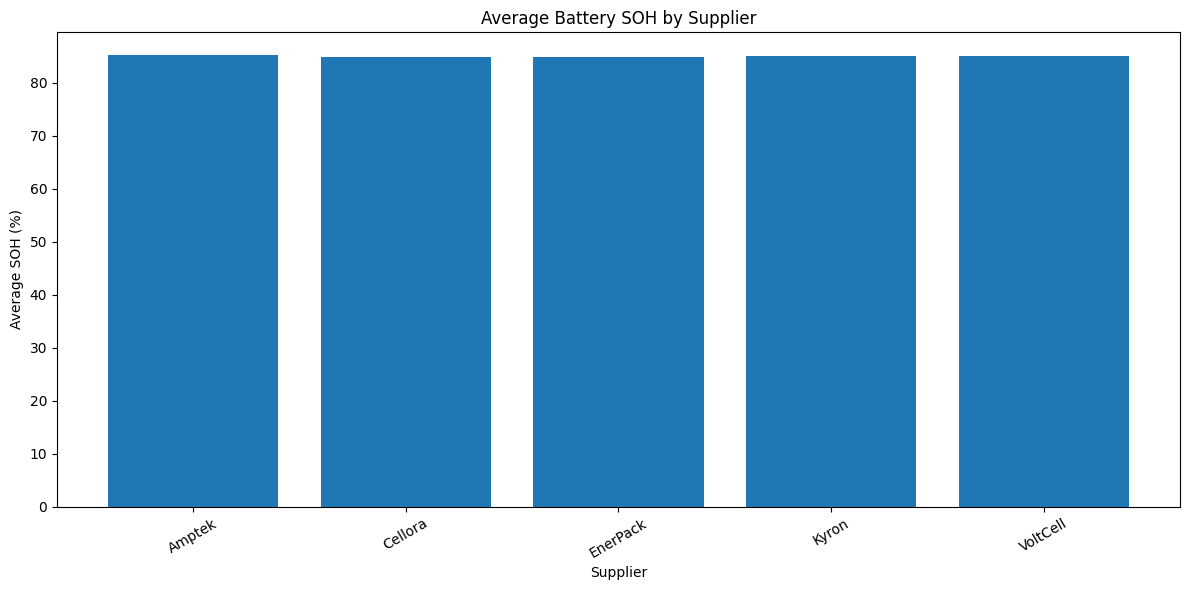

In [ ]:
plt.figure()

plt.bar(
    battery_analysis["supplier"],
    battery_analysis["avg_soh"]
)

plt.title(
    "Average Battery SOH by Supplier"
)

plt.xlabel("Supplier")
plt.ylabel("Average SOH (%)")

plt.xticks(
    rotation=30
)

plt.tight_layout()

plt.show()


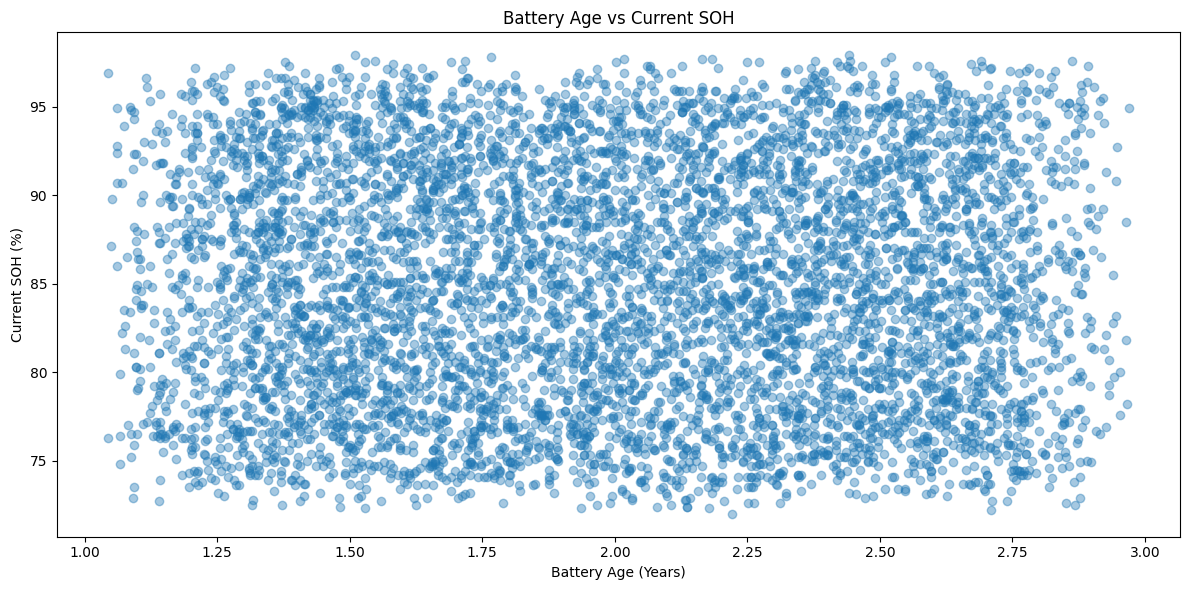

In [ ]:
today = pd.Timestamp("2025-12-31")

batteries["battery_age_days"] = (
    today -
    batteries["commission_date"]
).dt.days

batteries["battery_age_years"] = (
    batteries["battery_age_days"] / 365
)

plt.figure()

plt.scatter(
    batteries["battery_age_years"],
    batteries["current_soh_pct"],
    alpha=0.4
)

plt.title(
    "Battery Age vs Current SOH"
)

plt.xlabel(
    "Battery Age (Years)"
)

plt.ylabel(
    "Current SOH (%)"
)

plt.tight_layout()

plt.show()



In [ ]:
rider_activity = (
    business_swaps
    .groupby("rider_id")
    .agg(
        first_swap=(
            "event_ts",
            "min"
        ),
        total_attempts=(
            "event_id",
            "count"
        ),
        completed_swaps=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        failed_swaps=(
            "event_type",
            lambda x: (x != "swap_completed").sum()
        ),
        avg_wait=(
            "queue_wait_sec",
            "mean"
        ),
        total_spend=(
            "amount_charged_inr",
            "sum"
        )
    )
    .reset_index()
)

rider_activity["first_swap"] = pd.to_datetime(
    rider_activity["first_swap"]
)

max_date = business_swaps["event_ts"].max()

followup = business_swaps.merge(
    rider_activity[
        ["rider_id", "first_swap"]
    ],
    on="rider_id",
    how="left"
)

followup["days_after_first"] = (
    followup["event_ts"]
    - followup["first_swap"]
).dt.total_seconds() / 86400

returned = (
    followup[
        (followup["days_after_first"] > 7) &
        (followup["days_after_first"] <= 90) &
        (followup["event_type"] == "swap_completed")
    ]
    ["rider_id"]
    .drop_duplicates()
)

rider_activity["returned_90d"] = (
    rider_activity["rider_id"]
    .isin(returned)
)

rider_activity = rider_activity.merge(
    riders,
    on="rider_id",
    how="left"
)

print(
    "Overall 90-day return rate:",
    round(
        rider_activity["returned_90d"].mean() * 100,
        2
    ),
    "%"
)



Overall 90-day return rate: 52.98 %


In [ ]:
first_events = (
    business_swaps
    .sort_values("event_ts")
    .groupby("rider_id")
    .first()
    .reset_index()
)

first_events = first_events[
    [
        "rider_id",
        "event_type",
        "queue_wait_sec"
    ]
]

first_events = first_events.merge(
    rider_activity[
        ["rider_id", "returned_90d"]
    ],
    on="rider_id",
    how="left"
)

first_events["experience"] = np.where(
    first_events["event_type"] == "swap_completed",
    np.where(
        first_events["queue_wait_sec"] <= 120,
        "Successful + Low Wait",
        "Successful + High Wait"
    ),
    "Failed First Attempt"
)

retention_experience = (
    first_events
    .groupby("experience")
    .agg(
        riders=("rider_id", "count"),
        return_rate=("returned_90d", "mean")
    )
    .reset_index()
)

retention_experience["return_rate_pct"] = (
    retention_experience["return_rate"] * 100
)

display(
    retention_experience
)


,experience,riders,return_rate,return_rate_pct
0,Failed First Attempt,2448,0.540033,54.003268
1,Successful + High Wait,5798,0.522594,52.259400
2,Successful + Low Wait,11738,0.531181,53.118078


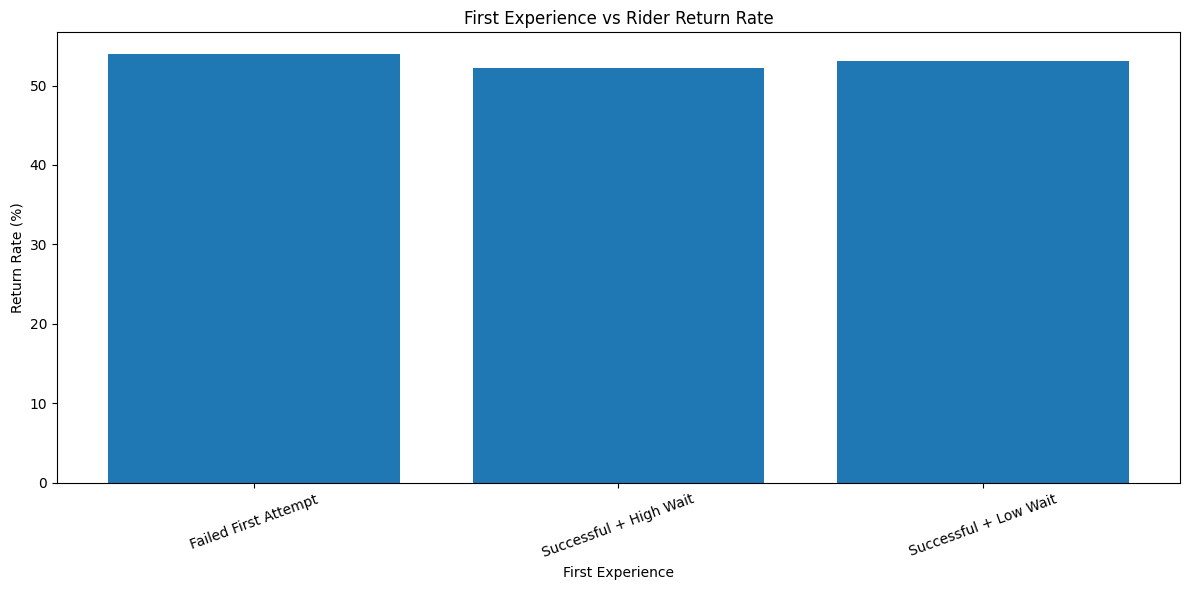

In [ ]:
plt.figure()

plt.bar(
    retention_experience["experience"],
    retention_experience["return_rate_pct"]
)

plt.title(
    "First Experience vs Rider Return Rate"
)

plt.xlabel("First Experience")
plt.ylabel("Return Rate (%)")

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.show()


In [ ]:
ticket_analysis = (
    tickets
    .groupby("category")
    .agg(
        tickets=("ticket_id", "count"),
        avg_resolution_hours=(
            "resolution_hours",
            "mean"
        ),
        avg_csat=(
            "csat_score",
            "mean"
        )
    )
    .reset_index()
)

display(ticket_analysis)


,category,tickets,avg_resolution_hours,avg_csat
0,app_issue,7333,24.477198,2.992205
1,battery_degradation,7517,24.287571,3.008914
2,long_queue,7212,24.258264,2.983907
3,other,7368,24.653078,2.985615
4,payment_issue,7288,24.783876,2.961311
5,station_issue,7282,24.708336,2.948813


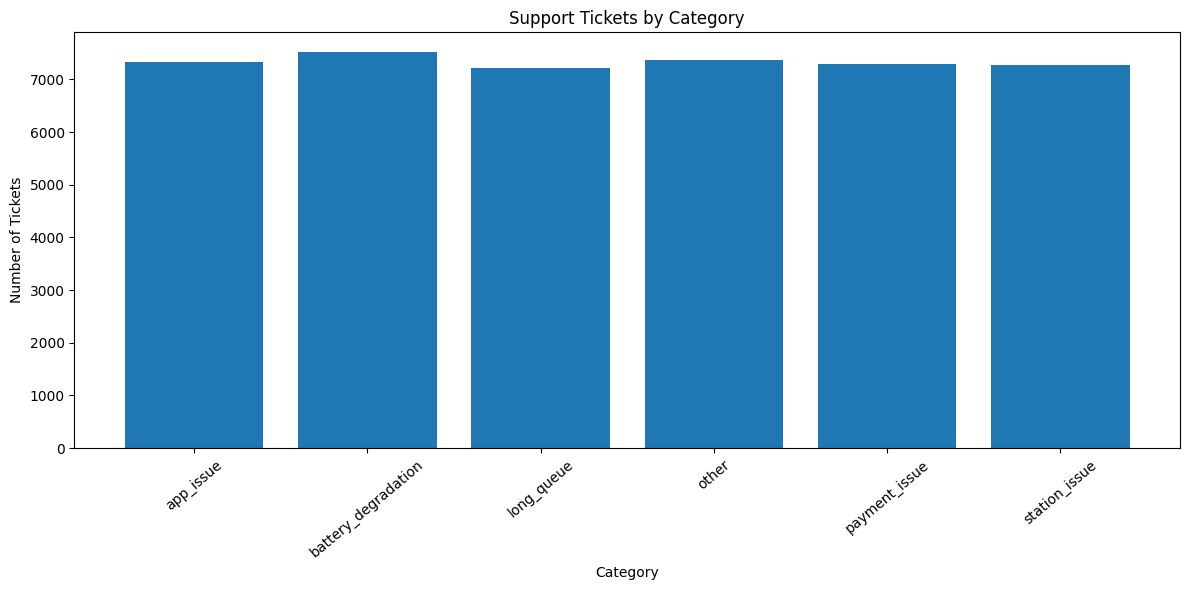

In [ ]:
plt.figure()

plt.bar(
    ticket_analysis["category"],
    ticket_analysis["tickets"]
)

plt.title(
    "Support Tickets by Category"
)

plt.xlabel("Category")
plt.ylabel("Number of Tickets")

plt.xticks(
    rotation=40
)

plt.tight_layout()

plt.show()



In [ ]:
pricing = (
    business_swaps
    .groupby("tariff_code")
    .agg(
        attempts=("event_id", "count"),
        completed=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        revenue=(
            "amount_charged_inr",
            "sum"
        ),
        avg_discount=(
            "discount_inr",
            "mean"
        )
    )
    .reset_index()
)

pricing["revenue_per_attempt"] = (
    pricing["revenue"]
    / pricing["attempts"]
)

pricing["completion_rate_pct"] = (
    pricing["completed"]
    / pricing["attempts"]
) * 100

display(pricing)


,tariff_code,attempts,completed,revenue,avg_discount,revenue_per_attempt,completion_rate_pct
0,OFFPEAK,24958,21971,2495040.00,0.000000,99.969549,88.031894
1,PARTNER,25038,22085,2126801.55,15.028295,84.942949,88.205927
2,PEAK,24945,21927,2493690.00,0.000000,99.967529,87.901383
3,PREPAID,25170,22122,2136166.85,15.025155,84.869561,87.890346
4,PROMO_FREE,24955,21900,2123893.81,14.957171,85.108949,87.757964
5,STD,24934,21906,2493970.00,0.000000,100.022860,87.855940


In [ ]:
business_swaps["energy_to_recharge_kwh"] = pd.to_numeric(
    business_swaps["energy_to_recharge_kwh"],
    errors="coerce"
)

business_swaps["energy_to_recharge_kwh"] = (
    business_swaps["energy_to_recharge_kwh"]
    .fillna(0)
)

business_swaps = business_swaps.merge(
    stations[
        [
            "station_id",
            "grid_tariff_inr_kwh"
        ]
    ],
    on="station_id",
    how="left"
)

business_swaps["energy_cost_inr"] = (
    business_swaps["energy_to_recharge_kwh"]
    * business_swaps["grid_tariff_inr_kwh"]
)



In [ ]:
business_swaps["contribution_margin_proxy"] = (
    business_swaps["amount_charged_inr"]
    - business_swaps["energy_cost_inr"]
)

margin_summary = (
    business_swaps
    .groupby("month")
    .agg(
        revenue=(
            "amount_charged_inr",
            "sum"
        ),
        energy_cost=(
            "energy_cost_inr",
            "sum"
        ),
        margin_proxy=(
            "contribution_margin_proxy",
            "sum"
        )
    )
    .reset_index()
)

display(margin_summary)


,month,revenue,energy_cost,margin_proxy
0,2024-01,601701.94,138021.6643,463680.2757
1,2024-02,545243.36,122839.9534,422403.4066
2,2024-03,584229.70,133671.7076,450557.9924
3,2024-04,566527.02,132123.4446,434403.5754
4,2024-05,593073.31,135820.2870,457253.0230
5,2024-06,573579.79,131587.0770,441992.7130
6,2024-07,586726.29,135499.0565,451227.2335
7,2024-08,589982.84,137115.9243,452866.9157
8,2024-09,569379.72,130970.7670,438408.9530
9,2024-10,589252.78,138623.7881,450628.9919


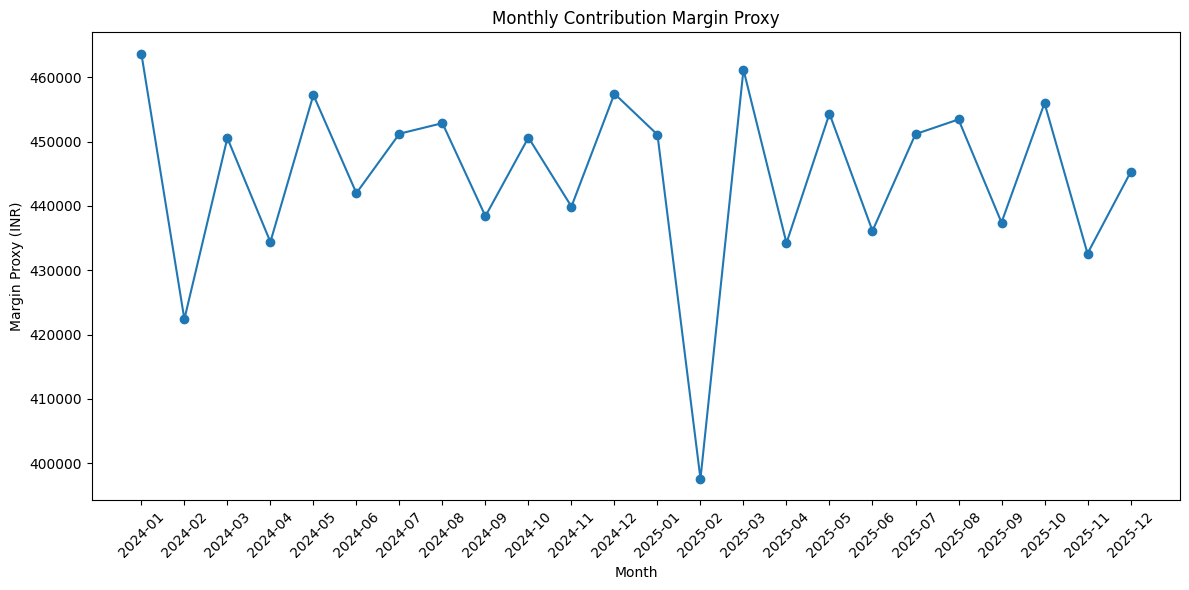

In [ ]:
plt.figure()

plt.plot(
    margin_summary["month"],
    margin_summary["margin_proxy"],
    marker="o"
)

plt.title(
    "Monthly Contribution Margin Proxy"
)

plt.xlabel("Month")
plt.ylabel("Margin Proxy (INR)")

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()



In [ ]:
business_swaps["contribution_margin_proxy"] = (
    business_swaps["amount_charged_inr"]
    - business_swaps["energy_cost_inr"]
)

margin_summary = (
    business_swaps
    .groupby("month")
    .agg(
        revenue=(
            "amount_charged_inr",
            "sum"
        ),
        energy_cost=(
            "energy_cost_inr",
            "sum"
        ),
        margin_proxy=(
            "contribution_margin_proxy",
            "sum"
        )
    )
    .reset_index()
)

display(margin_summary)


,month,revenue,energy_cost,margin_proxy
0,2024-01,601701.94,138021.6643,463680.2757
1,2024-02,545243.36,122839.9534,422403.4066
2,2024-03,584229.70,133671.7076,450557.9924
3,2024-04,566527.02,132123.4446,434403.5754
4,2024-05,593073.31,135820.2870,457253.0230
5,2024-06,573579.79,131587.0770,441992.7130
6,2024-07,586726.29,135499.0565,451227.2335
7,2024-08,589982.84,137115.9243,452866.9157
8,2024-09,569379.72,130970.7670,438408.9530
9,2024-10,589252.78,138623.7881,450628.9919


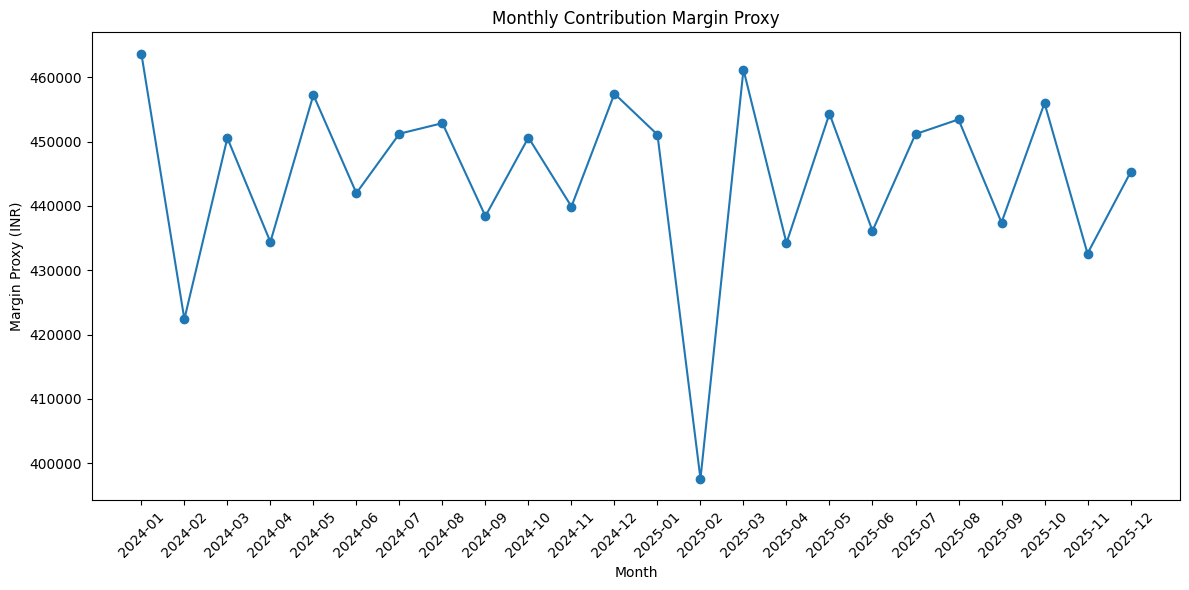

In [ ]:
plt.figure()

plt.plot(
    margin_summary["month"],
    margin_summary["margin_proxy"],
    marker="o"
)

plt.title(
    "Monthly Contribution Margin Proxy"
)

plt.xlabel("Month")
plt.ylabel("Margin Proxy (INR)")

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


In [ ]:
daily_swaps = (
    business_swaps
    .assign(
        date=business_swaps["event_ts"].dt.date
    )
    .groupby("date")
    .agg(
        attempts=("event_id", "count"),
        completed=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        avg_wait=(
            "queue_wait_sec",
            "mean"
        )
    )
    .reset_index()
)

daily_swaps["date"] = pd.to_datetime(
    daily_swaps["date"]
)

city_context["date"] = pd.to_datetime(
    city_context["date"]
)

weather_analysis = daily_swaps.merge(
    city_context[
        [
            "date",
            "city",
            "rainfall_mm",
            "heat_alert",
            "flood_disruption",
            "grid_outage_hours"
        ]
    ],
    on="date",
    how="left"
)

weather_analysis["failure_rate_pct"] = (
    1 -
    weather_analysis["completed"]
    / weather_analysis["attempts"]
) * 100

display(
    weather_analysis.head(20)
)

,date,attempts,completed,avg_wait,city,rainfall_mm,heat_alert,flood_disruption,grid_outage_hours,failure_rate_pct
0,2024-01-01,199,177,108.100503,Bengaluru,0.0,False,False,1.7,11.055276
1,2024-01-01,199,177,108.100503,Delhi NCR,0.0,False,False,0.0,11.055276
2,2024-01-01,199,177,108.100503,Hyderabad,0.0,False,False,0.0,11.055276
3,2024-01-01,199,177,108.100503,Pune,0.0,False,False,1.4,11.055276
4,2024-01-01,199,177,108.100503,Mumbai,0.0,False,False,0.2,11.055276
5,2024-01-01,199,177,108.100503,Jaipur,0.0,False,False,0.0,11.055276
6,2024-01-02,211,188,112.763033,Bengaluru,0.0,False,False,0.8,10.900474
7,2024-01-02,211,188,112.763033,Delhi NCR,0.0,False,False,0.3,10.900474
8,2024-01-02,211,188,112.763033,Hyderabad,0.0,True,False,2.9,10.900474
9,2024-01-02,211,188,112.763033,Pune,0.0,False,False,0.8,10.900474


In [ ]:
print("\n")
print("=" * 70)
print("                 VOLTRELAY KPI SUMMARY")
print("=" * 70)

print(
    f"Total Attempts       : {len(business_swaps):,}"
)

print(
    f"Completed Swaps      : {(business_swaps['event_type'] == 'swap_completed').sum():,}"
)

print(
    f"Failure Rate         : {failure_rate:.2f}%"
)

print(
    f"Total Revenue        : ₹{revenue:,.2f}"
)

print(
    f"Revenue / Attempt    : ₹{revenue_per_attempt:.2f}"
)

print(
    f"Rider Return Rate    : "
    f"{rider_activity['returned_90d'].mean() * 100:.2f}%"
)

print(
    f"Average Battery SOH  : "
    f"{batteries['current_soh_pct'].mean():.2f}%"
)

print(
    f"Support Tickets      : {len(tickets):,}"
)

print("=" * 70)




                 VOLTRELAY KPI SUMMARY
Total Attempts       : 150,000
Completed Swaps      : 131,911
Failure Rate         : 12.06%
Total Revenue        : ₹13,869,562.21
Revenue / Attempt    : ₹92.46
Rider Return Rate    : 52.98%
Average Battery SOH  : 84.98%
Support Tickets      : 44,000


In [ ]:
print("\nKEY FINDINGS")

worst_city = city_analysis.loc[
    city_analysis["failure_rate_pct"].idxmax()
]

worst_station = station_analysis.loc[
    station_analysis["failure_rate_pct"].idxmax()
]

best_battery_supplier = battery_analysis.loc[
    battery_analysis["avg_soh"].idxmax()
]

highest_ticket_category = ticket_analysis.loc[
    ticket_analysis["tickets"].idxmax()
]

print(
    f"""
1. City with highest observed failure rate:
   {worst_city['city']}
   Failure rate: {worst_city['failure_rate_pct']:.2f}%

2. Station with highest observed failure rate:
   {worst_station['station_id']}
   Failure rate: {worst_station['failure_rate_pct']:.2f}%

3. Supplier with highest average battery SOH:
   {best_battery_supplier['supplier']}
   Average SOH: {best_battery_supplier['avg_soh']:.2f}%

4. Most common support-ticket category:
   {highest_ticket_category['category']}
   Tickets: {int(highest_ticket_category['tickets']):,}

5. Overall rider 90-day return rate:
   {rider_activity['returned_90d'].mean() * 100:.2f}%
"""
)


KEY FINDINGS

1. City with highest observed failure rate:
   Jaipur
   Failure rate: 12.30%

2. Station with highest observed failure rate:
   STN-127
   Failure rate: 14.80%

3. Supplier with highest average battery SOH:
   Amptek
   Average SOH: 85.24%

4. Most common support-ticket category:
   battery_degradation
   Tickets: 7,517

5. Overall rider 90-day return rate:
   52.98%



In [ ]:
monthly.to_csv(
    "monthly_network_analysis.csv",
    index=False
)

city_analysis.to_csv(
    "city_analysis.csv",
    index=False
)

station_analysis.to_csv(
    "station_analysis.csv",
    index=False
)

battery_analysis.to_csv(
    "battery_analysis.csv",
    index=False
)

retention_experience.to_csv(
    "retention_analysis.csv",
    index=False
)

pricing.to_csv(
    "pricing_analysis.csv",
    index=False
)

margin_summary.to_csv(
    "margin_analysis.csv",
    index=False
)

print("\nAnalysis CSV files saved successfully!")


Analysis CSV files saved successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print(" Starting VoltRelay Dashboard...")

 Starting VoltRelay Dashboard...


In [ ]:
BASE_DIR = "VoltRelay_Dataset"

swap = pd.read_csv(f"{BASE_DIR}/swap_events.csv")
stations = pd.read_csv(f"{BASE_DIR}/stations.csv")
riders = pd.read_csv(f"{BASE_DIR}/riders.csv")
batteries = pd.read_csv(f"{BASE_DIR}/batteries.csv")
city_context = pd.read_csv(f"{BASE_DIR}/city_daily_context.csv")
station_status = pd.read_csv(f"{BASE_DIR}/station_hourly_status.csv")
support = pd.read_csv(f"{BASE_DIR}/support_tickets.csv")

swap["event_ts"] = pd.to_datetime(
    swap["event_ts"], errors="coerce"
)

swap["date"] = swap["event_ts"].dt.date
swap["month"] = swap["event_ts"].dt.to_period("M").astype(str)
swap["hour"] = swap["event_ts"].dt.hour


In [ ]:
total_attempts = len(swap)

completed = (
    swap["event_type"].astype(str).str.lower() == "swap_completed"
).sum()

failed = total_attempts - completed

completion_rate = (
    completed / total_attempts * 100
    if total_attempts > 0 else 0
)

failure_rate = (
    failed / total_attempts * 100
    if total_attempts > 0 else 0
)

revenue = swap.loc[
    swap["event_type"].astype(str).str.lower() == "swap_completed",
    "amount_charged_inr"
].sum()

avg_revenue = (
    revenue / completed
    if completed > 0 else 0
)

print("\n" + "="*60)
print("VOLTRELAY NETWORK KPI DASHBOARD")
print("="*60)

print(f"Total Swap Attempts : {total_attempts:,}")
print(f"Completed Swaps    : {completed:,}")
print(f"Failed Swaps       : {failed:,}")
print(f"Completion Rate    : {completion_rate:.2f}%")
print(f"Failure Rate       : {failure_rate:.2f}%")
print(f"Total Revenue      : ₹{revenue:,.2f}")
print(f"Revenue / Swap     : ₹{avg_revenue:,.2f}")


VOLTRELAY NETWORK KPI DASHBOARD
Total Swap Attempts : 150,500
Completed Swaps    : 132,338
Failed Swaps       : 18,162
Completion Rate    : 87.93%
Failure Rate       : 12.07%
Total Revenue      : ₹12,236,873.13
Revenue / Swap     : ₹92.47


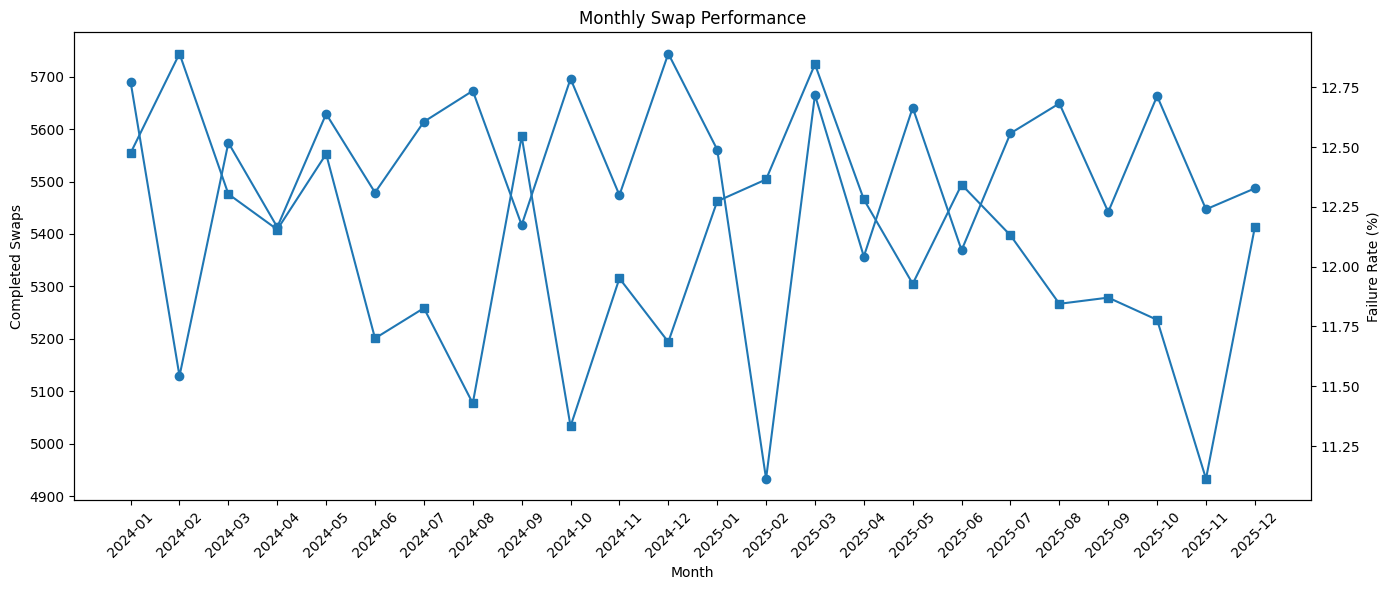

In [ ]:
monthly = swap.groupby("month").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum()),
    revenue=("amount_charged_inr", "sum")
).reset_index()

monthly["failure_rate"] = (
    1 - monthly["completed"] / monthly["attempts"]
) * 100

fig, ax1 = plt.subplots(figsize=(14,6))

ax1.plot(
    monthly["month"],
    monthly["completed"],
    marker="o",
    label="Completed Swaps"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Completed Swaps")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()

ax2.plot(
    monthly["month"],
    monthly["failure_rate"],
    marker="s",
    label="Failure Rate"
)

ax2.set_ylabel("Failure Rate (%)")

plt.title("Monthly Swap Performance")
plt.tight_layout()
plt.show()

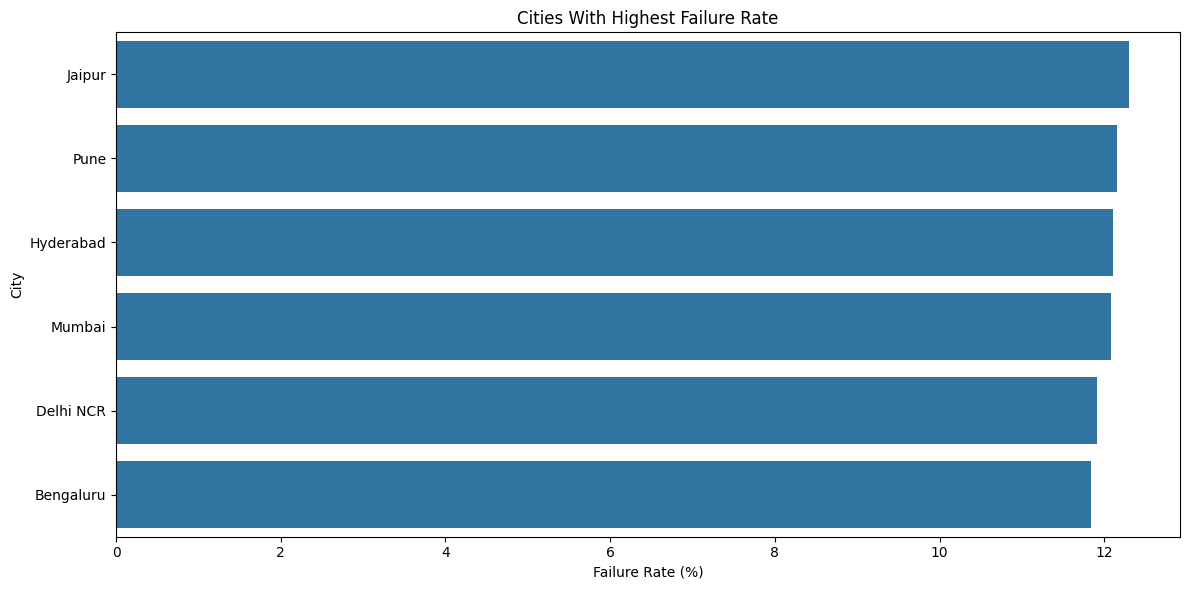

In [ ]:
city_analysis = swap.merge(stations[['station_id', 'city']], on='station_id', how='left')

city_agg = city_analysis.groupby("city").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum()),
    revenue=("amount_charged_inr", "sum")
).reset_index()

city_agg["failure_rate"] = (
    1 - city_agg["completed"] / city_agg["attempts"]
) * 100

city_agg = city_agg.sort_values("failure_rate", ascending=False)

plt.figure(figsize=(12,6))

sns.barplot(
    data=city_agg.head(15),
    x="failure_rate",
    y="city"
)

plt.title("Cities With Highest Failure Rate")
plt.xlabel("Failure Rate (%)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

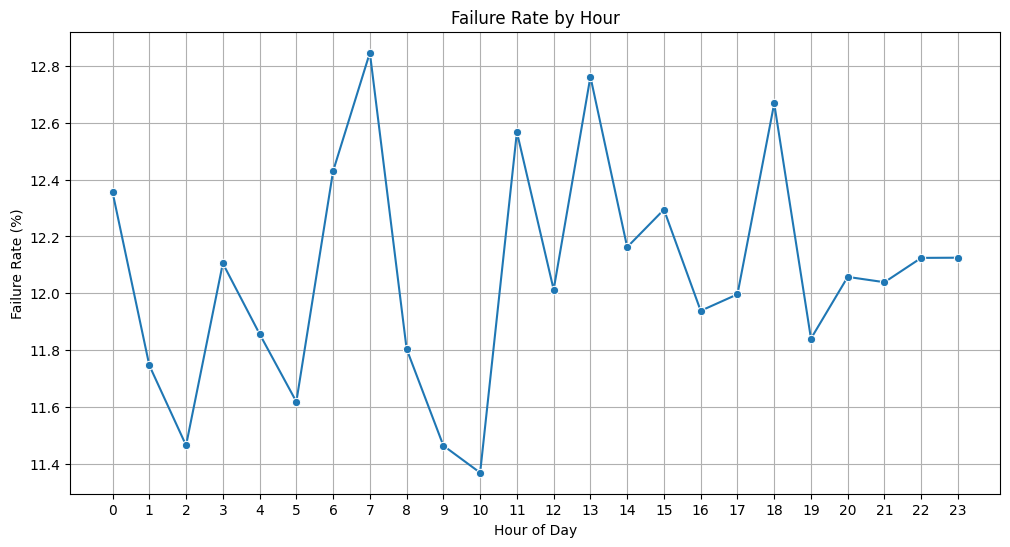

In [ ]:
hourly = swap.groupby("hour").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum())
).reset_index()

hourly["failure_rate"] = (
    1 - hourly["completed"] / hourly["attempts"]
) * 100

plt.figure(figsize=(12,6))

sns.lineplot(
    data=hourly,
    x="hour",
    y="failure_rate",
    marker="o"
)

plt.title("Failure Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Failure Rate (%)")
plt.xticks(range(0,24))
plt.grid(True)
plt.show()

In [ ]:
station_perf = swap.groupby("station_id").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum()),
    revenue=("amount_charged_inr", "sum")
).reset_index()

station_perf["failure_rate"] = (
    1 - station_perf["completed"] /
    station_perf["attempts"]
) * 100

station_perf = station_perf.merge(
    stations,
    on="station_id",
    how="left"
)

print("\nTop 10 High-Failure Stations")

display(
    station_perf.sort_values(
        "failure_rate",
        ascending=False
    ).head(10)
)


Top 10 High-Failure Stations


,station_id,attempts,completed,revenue,failure_rate,city,zone,latitude,longitude,location_type,...,slots_3w,inventory_target_2w,inventory_target_3w,monthly_rent_inr,monthly_maintenance_inr,grid_tariff_inr_kwh,connectivity_tier,firmware_version,firmware_updated_date,competitor_within_1_5km_since
126,STN-127,1004,856,92979.68,14.741036,Jaipur,Zone_3,26.991705,75.753646,commercial_hub,...,10,10,3,21160,7457,9.08,poor,v3.3.0,2026-02-21,NaN
123,STN-124,1044,895,96207.99,14.272031,Mumbai,Zone_7,19.081291,72.940743,commercial_hub,...,6,10,5,32414,3160,8.61,poor,v3.0.0,2024-07-02,NaN
28,STN-029,1017,873,94175.28,14.159292,Delhi NCR,Zone_7,28.538771,77.246736,owned_lot,...,4,18,7,20561,7445,7.00,good,v3.1.0,2025-12-04,NaN
86,STN-087,1047,899,96740.54,14.135626,Pune,Zone_3,18.602542,73.767783,owned_lot,...,8,14,3,18211,4108,8.54,poor,v3.2.0,2024-05-07,NaN
20,STN-021,1025,882,94518.45,13.951220,Bengaluru,Zone_4,12.873630,77.684213,market_area,...,10,18,3,13049,4910,6.89,poor,v3.1.0,2024-07-18,NaN
136,STN-137,1007,867,92912.39,13.902681,Jaipur,Zone_3,26.887224,75.779913,owned_lot,...,10,6,3,33925,3660,7.39,fair,v3.3.0,2025-03-28,NaN
93,STN-094,1031,889,95852.83,13.773036,Pune,Zone_8,18.531045,73.771406,residential_hub,...,10,14,5,28279,5495,9.02,good,v3.3.0,2025-05-29,NaN
1,STN-002,992,856,91650.56,13.709677,Bengaluru,Zone_1,12.959967,77.635733,commercial_hub,...,8,10,5,14176,2842,7.23,good,v3.2.0,2025-01-29,NaN
103,STN-104,1012,874,93501.77,13.636364,Mumbai,Zone_8,19.066870,72.905962,transit_hub,...,4,14,3,33957,6259,8.59,poor,v3.1.0,2024-10-02,NaN
134,STN-135,1027,887,95318.91,13.631938,Jaipur,Zone_7,26.862936,75.718129,commercial_hub,...,10,6,5,32991,6898,8.38,good,v3.0.0,2025-09-01,NaN


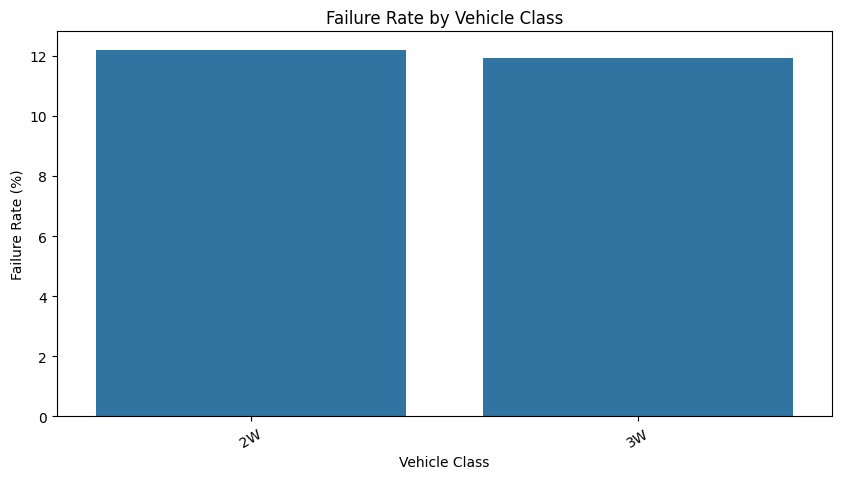

In [ ]:
vehicle = swap.merge(
    riders[['rider_id', 'vehicle_class']],
    on='rider_id',
    how='left'
).groupby("vehicle_class").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum())
).reset_index()

vehicle["failure_rate"] = (
    1 - vehicle["completed"] / vehicle["attempts"]
) * 100

plt.figure(figsize=(10,5))

sns.barplot(
    data=vehicle,
    x="vehicle_class",
    y="failure_rate"
)

plt.title("Failure Rate by Vehicle Class")
plt.xlabel("Vehicle Class")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=30)
plt.show()

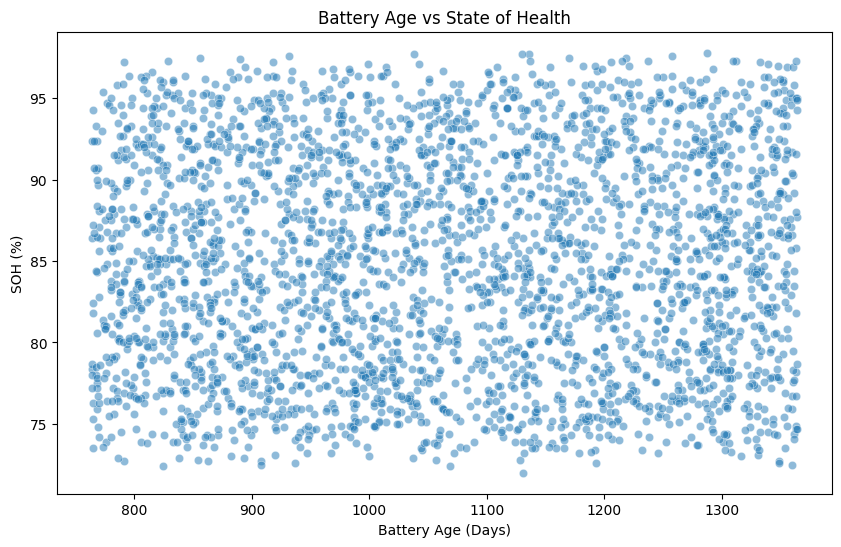

In [ ]:
batteries["manufacture_date"] = pd.to_datetime(
    batteries["manufacture_date"],
    errors="coerce"
)

batteries["battery_age_days"] = (
    pd.Timestamp.today() -
    batteries["manufacture_date"]
).dt.days

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=batteries.sample(
        min(3000, len(batteries)),
        random_state=42
    ),
    x="battery_age_days",
    y="current_soh_pct",
    alpha=0.5
)

plt.title("Battery Age vs State of Health")
plt.xlabel("Battery Age (Days)")
plt.ylabel("SOH (%)")
plt.show()

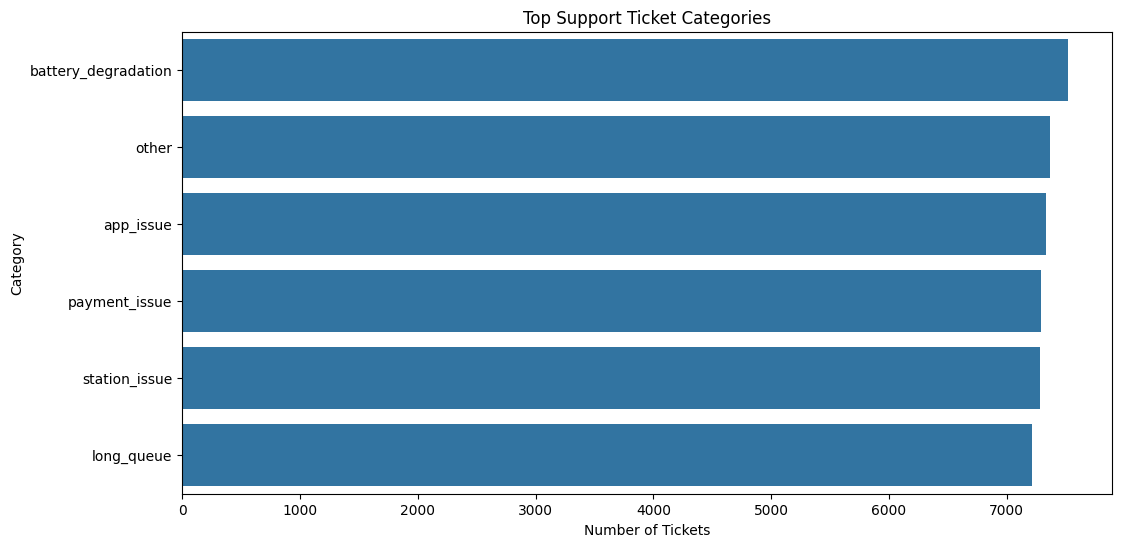

In [ ]:
ticket_counts = (
    support["category"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=ticket_counts.values,
    y=ticket_counts.index
)

plt.title("Top Support Ticket Categories")
plt.xlabel("Number of Tickets")
plt.ylabel("Category")
plt.show()

In [ ]:
dashboard_summary = pd.DataFrame({
    "Metric": [
        "Total Swap Attempts",
        "Completed Swaps",
        "Failed Swaps",
        "Completion Rate",
        "Failure Rate",
        "Total Revenue",
        "Average Revenue per Completed Swap",
        "Number of Stations",
        "Number of Riders",
        "Number of Batteries"
    ],
    "Value": [
        total_attempts,
        completed,
        failed,
        round(completion_rate,2),
        round(failure_rate,2),
        round(revenue,2),
        round(avg_revenue,2),
        stations["station_id"].nunique(),
        riders["rider_id"].nunique(),
        batteries["battery_id"].nunique()
    ]
})

print("\n FINAL DASHBOARD")
display(dashboard_summary)

dashboard_summary.to_csv(
    "VoltRelay_Dashboard_KPIs.csv",
    index=False
)

print("✅ Cell 3 completed!")


 FINAL DASHBOARD


,Metric,Value
0,Total Swap Attempts,150500.00
1,Completed Swaps,132338.00
2,Failed Swaps,18162.00
3,Completion Rate,87.93
4,Failure Rate,12.07
5,Total Revenue,12236873.13
6,Average Revenue per Completed Swap,92.47
7,Number of Stations,150.00
8,Number of Riders,20000.00
9,Number of Batteries,6500.00


✅ Cell 3 completed!


In [ ]:
import pandas as pd
import numpy as np
import os

print(" Generating final VoltRelay insights...")

 Generating final VoltRelay insights...


In [ ]:
total_attempts = len(swap)

completed = (
    swap["event_type"].astype(str).str.lower() == "swap_completed"
).sum()

failed = total_attempts - completed

completion_rate = completed / total_attempts * 100
failure_rate = failed / total_attempts * 100

In [ ]:
city_analysis_df = swap.merge(stations[['station_id', 'city']], on='station_id', how='left')

city = city_analysis_df.groupby("city").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum())
).reset_index()

city["failure_rate"] = (
    1 - city["completed"] / city["attempts"]
) * 100

worst_city = city.loc[
    city["failure_rate"].idxmax()
]

In [ ]:
hourly = swap.groupby("hour").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum())
).reset_index()

hourly["failure_rate"] = (
    1 - hourly["completed"] / hourly["attempts"]
) * 100

worst_hour = hourly.loc[
    hourly["failure_rate"].idxmax()
]

In [ ]:
station_perf = swap.groupby("station_id").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum())
).reset_index()

station_perf["failure_rate"] = (
    1 - station_perf["completed"] /
    station_perf["attempts"]
) * 100

worst_station = station_perf.loc[
    station_perf["failure_rate"].idxmax()
]

In [ ]:
vehicle_analysis_df = swap.merge(riders[['rider_id', 'vehicle_class']], on='rider_id', how='left')

vehicle = vehicle_analysis_df.groupby("vehicle_class").agg(
    attempts=("event_id", "count"),
    completed=("event_type", lambda x:
               (x.astype(str).str.lower() == "swap_completed").sum())
).reset_index()

vehicle["failure_rate"] = (
    1 - vehicle["completed"] /
    vehicle["attempts"]
) * 100

worst_vehicle = vehicle.loc[
    vehicle["failure_rate"].idxmax()
]

In [ ]:
avg_soh = batteries["current_soh_pct"].mean()

low_soh_count = (
    batteries["current_soh_pct"] < 80
).sum()

low_soh_percent = (
    low_soh_count / len(batteries) * 100
)

In [ ]:
top_ticket = (
    support["category"]
    .value_counts()
    .idxmax()
)

top_ticket_count = (
    support["category"]
    .value_counts()
    .max()
)

In [ ]:
findings = []

findings.append(
    f"1. Network completion rate is {completion_rate:.2f}%, "
    f"while failure rate is {failure_rate:.2f}%."
)

findings.append(
    f"2. {worst_city['city']} has the highest observed "
    f"failure rate at {worst_city['failure_rate']:.2f}%."
)

findings.append(
    f"3. Hour {int(worst_hour['hour']):02d}:00 shows the "
    f"highest observed hourly failure rate of "
    f"{worst_hour['failure_rate']:.2f}%."
)

findings.append(
    f"4. Station {worst_station['station_id']} has the "
    f"highest observed station failure rate of "
    f"{worst_station['failure_rate']:.2f}%."
)

findings.append(
    f"5. {worst_vehicle['vehicle_class']} shows the highest "
    f"failure rate among vehicle classes at "
    f"{worst_vehicle['failure_rate']:.2f}%."
)

findings.append(
    f"6. Average battery SOH is {avg_soh:.2f}%. "
    f"{low_soh_percent:.2f}% of batteries have SOH below 80%."
)

findings.append(
    f"7. The most common support-ticket category is "
    f"'{top_ticket}', with {top_ticket_count:,} tickets."
)


In [ ]:
recommendations = [
    "Prioritize high-failure cities and stations for operational investigation.",

    "Investigate peak failure hours and align staffing, battery inventory, "
    "and maintenance capacity with demand.",

    "Monitor stations with repeated failures and identify equipment, "
    "connectivity, charger, or capacity-related causes.",

    "Track battery SOH and age to identify batteries that may require "
    "maintenance, rotation, or retirement.",

    "Use rider failure and support-ticket patterns to improve the "
    "first swap experience and reduce repeated service issues.",

    "Monitor pricing, revenue, energy cost, operating cost, and battery "
    "wear together before making expansion decisions.",

    "Use weather and disruption information as contextual variables "
    "when investigating unusual changes in demand or service failures."
]


In [ ]:
print("\n")
print("="*70)
print(" VOLTRELay HACKATHON - FINAL ANALYTICS REPORT")
print("="*70)

print("\n KEY FINDINGS")
print("-"*70)

for finding in findings:
    print(finding)

print("\n BUSINESS RECOMMENDATIONS")
print("-"*70)

for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")

print("\n" + "="*70)




 VOLTRELay HACKATHON - FINAL ANALYTICS REPORT

 KEY FINDINGS
----------------------------------------------------------------------
1. Network completion rate is 87.93%, while failure rate is 12.07%.
2. Jaipur has the highest observed failure rate at 12.30%.
3. Hour 07:00 shows the highest observed hourly failure rate of 12.85%.
4. Station STN-127 has the highest observed station failure rate of 14.74%.
5. 2W shows the highest failure rate among vehicle classes at 12.20%.
6. Average battery SOH is 84.98%. 27.94% of batteries have SOH below 80%.
7. The most common support-ticket category is 'battery_degradation', with 7,517 tickets.

 BUSINESS RECOMMENDATIONS
----------------------------------------------------------------------
1. Prioritize high-failure cities and stations for operational investigation.
2. Investigate peak failure hours and align staffing, battery inventory, and maintenance capacity with demand.
3. Monitor stations with repeated failures and identify equipment, conn

In [ ]:
report_lines = []

report_lines.append("VOLTRELAY DATA ANALYTICS HACKATHON")
report_lines.append("="*60)
report_lines.append("")
report_lines.append("KEY FINDINGS")
report_lines.append("")

report_lines.extend(findings)

report_lines.append("")
report_lines.append("BUSINESS RECOMMENDATIONS")
report_lines.append("")

for i, recommendation in enumerate(recommendations, 1):
    report_lines.append(
        f"{i}. {recommendation}"
    )

with open(
    "VoltRelay_Final_Report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(report_lines))

print("\n Final report saved as:")
print("VoltRelay_Final_Report.txt")


 Final report saved as:
VoltRelay_Final_Report.txt


In [ ]:
import os
import shutil
import glob
import zipfile

print(" Preparing VoltRelay submission package...")


 Preparing VoltRelay submission package...


In [ ]:
SUBMISSION_DIR = "VoltRelay_Hackathon_Submission"

if os.path.exists(SUBMISSION_DIR):
    shutil.rmtree(SUBMISSION_DIR)

os.makedirs(SUBMISSION_DIR)


In [ ]:
dataset_destination = os.path.join(
    SUBMISSION_DIR,
    "Dataset"
)

shutil.copytree(
    "VoltRelay_Dataset",
    dataset_destination
)

'VoltRelay_Hackathon_Submission/Dataset'

In [ ]:
files_to_copy = [
    "VoltRelay_Dashboard_KPIs.csv",
    "VoltRelay_Final_Report.txt"
]

for file in files_to_copy:

    if os.path.exists(file):

        shutil.copy(
            file,
            os.path.join(
                SUBMISSION_DIR,
                file
            )
        )


In [ ]:
readme = """
VOLTRELAY DATA ANALYTICS HACKATHON
==================================

Project:
VoltRelay EV Battery Swapping Network Analytics

Notebook workflow:
1. Data Generation / Data Loading
2. Data Understanding
3. Data Cleaning
4. Exploratory Data Analysis
5. Network Performance Analysis
6. Failure Analysis
7. Station Analysis
8. Battery Analysis
9. Rider Retention Analysis
10. Support Analysis
11. Pricing and Profitability Analysis
12. Weather / Context Analysis
13. Dashboard Visualizations
14. Key Findings
15. Business Recommendations

Main outputs:
- VoltRelay_Dashboard_KPIs.csv
- VoltRelay_Final_Report.txt
- Dataset/

IMPORTANT:
If official VoltRelay CSV files are provided by the hackathon organizers,
replace the synthetic dataset with the official dataset before final submission.
"""

with open(
    os.path.join(SUBMISSION_DIR, "README.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(readme)


In [ ]:
ZIP_NAME = "VoltRelay_Hackathon_Final_Submission.zip"

if os.path.exists(ZIP_NAME):
    os.remove(ZIP_NAME)

shutil.make_archive(
    "VoltRelay_Hackathon_Final_Submission",
    "zip",
    SUBMISSION_DIR
)


'/content/VoltRelay_Hackathon_Final_Submission.zip'

In [ ]:
print("\n SUBMISSION PACKAGE")
print("="*60)

for root, dirs, files in os.walk(SUBMISSION_DIR):

    level = root.replace(
        SUBMISSION_DIR, ""
    ).count(os.sep)

    indent = "  " * level

    print(
        indent +
        os.path.basename(root) +
        "/"
    )

    for file in files:
        print(
            indent +
            "   " +
            file
        )

print("\n" + "="*60)
print(" HACKATHON PACKAGE CREATED!")
print("="*60)

print(f"\n ZIP FILE:")
print(ZIP_NAME)

print("\nYou can download the ZIP from the Colab Files panel.")


 SUBMISSION PACKAGE
VoltRelay_Hackathon_Submission/
   VoltRelay_Dashboard_KPIs.csv
   VoltRelay_Final_Report.txt
   README.txt
  Dataset/
     fleet_partners.csv
     support_tickets.csv
     city_daily_context.csv
     station_hourly_status.csv
     stations.csv
     batteries.csv
     swap_events.csv
     riders.csv

 HACKATHON PACKAGE CREATED!

 ZIP FILE:
VoltRelay_Hackathon_Final_Submission.zip

You can download the ZIP from the Colab Files panel.


In [1]:
!git config --global user.name "srilekab2024laiml-lang"
!git config --global user.email "srileka.b2024laiml@sece.ac.in"


!git clone https://github.com/srilekab2024laiml-lang/Data-Analytics-Challenge-Hackathon.git


%cd Data-Analytics-Challenge-Hackathon


!git status
!ls -la

Cloning into 'Data-Analytics-Challenge-Hackathon'...
/content/Data-Analytics-Challenge-Hackathon
On branch main

No commits yet

nothing to commit (create/copy files and use "git add" to track)
total 12
drwxr-xr-x 3 root root 4096 Sep 27 03:15 .
drwxr-xr-x 1 root root 4096 Sep 27 03:15 ..
drwxr-xr-x 7 root root 4096 Sep 27 03:15 .git


In [ ]:
from google.colab import files

uploaded = files.upload()